# Classroom Ventilation Explorer

A Julia single-zone simulation comparing closed, half-open and fully open windows, with manual numerical solvers and paired Monte Carlo uncertainty analysis. This is an illustrative, uncalibrated model.

**Provenance:** the owner supplied the original model plan. Earlier implementation used substantial Codex assistance. This notebook and its packaging were AI-generated during a documented rebuild. Owner review is not assumed. Select a **Julia** Colab runtime, then Run all. Charts use a bundled lightweight SVG renderer; no Plots, GR or graphical native libraries are installed. The first and last cells report setup and total elapsed seconds. No machine-specific paths or repository URL are required.


In [1]:
notebook_started_ns = time_ns()
println("Julia version: ", VERSION)
ENV["JULIA_PKG_PRECOMPILE_AUTO"] = "0"
import Pkg
notebook_root = mktempdir()
bundled_files = Dict(
    "Project.toml" => "name = \"ClassroomVentilation\"\nuuid = \"ab317d88-e9a8-4c3f-b234-139feadeb783\"\nversion = \"0.1.0\"\n\n[deps]\nDates = \"ade2ca70-3891-5945-98fb-dc099432e06a\"\nDownloads = \"f43a241f-c20a-4ad4-852c-f6b1247861c6\"\nJSON = \"682c06a0-de6a-54ab-a142-c8b1cf79cde6\"\nRandom = \"9a3f8284-a2c9-5f02-9a11-845980a1fd5c\"\nSHA = \"ea8e919c-243c-51af-8825-aaa63cd721ce\"\nStatistics = \"10745b16-79ce-11e8-11f9-7d13ad32a3b2\"\n\n[compat]\nJSON = \"1\"\nStatistics = \"1\"\njulia = \"1.12\"\n\n[extras]\nTest = \"8dfed614-e22c-5e08-85e1-65c5234f0b40\"\n\n[targets]\ntest = [\"Test\"]\n",
    "Manifest.toml" => "# This file is machine-generated - editing it directly is not advised\n\njulia_version = \"1.12.7\"\nmanifest_format = \"2.0\"\nproject_hash = \"07985878ec17573b984c7dbdf60793041bd48f0a\"\n\n[[deps.ArgTools]]\nuuid = \"0dad84c5-d112-42e6-8d28-ef12dabb789f\"\nversion = \"1.1.2\"\n\n[[deps.Artifacts]]\nuuid = \"56f22d72-fd6d-98f1-02f0-08ddc0907c33\"\nversion = \"1.11.0\"\n\n[[deps.Base64]]\nuuid = \"2a0f44e3-6c83-55bd-87e4-b1978d98bd5f\"\nversion = \"1.11.0\"\n\n[[deps.ClassroomVentilation]]\ndeps = [\"Dates\", \"Downloads\", \"JSON\", \"Random\", \"SHA\", \"Statistics\"]\npath = \".\"\nuuid = \"ab317d88-e9a8-4c3f-b234-139feadeb783\"\nversion = \"0.1.0\"\n\n[[deps.CompilerSupportLibraries_jll]]\ndeps = [\"Artifacts\", \"Libdl\"]\nuuid = \"e66e0078-7015-5450-92f7-15fbd957f2ae\"\nversion = \"1.3.1+2\"\n\n[[deps.Dates]]\ndeps = [\"Printf\"]\nuuid = \"ade2ca70-3891-5945-98fb-dc099432e06a\"\nversion = \"1.11.0\"\n\n[[deps.Downloads]]\ndeps = [\"ArgTools\", \"FileWatching\", \"LibCURL\", \"NetworkOptions\"]\nuuid = \"f43a241f-c20a-4ad4-852c-f6b1247861c6\"\nversion = \"1.7.0\"\n\n[[deps.FileWatching]]\nuuid = \"7b1f6079-737a-58dc-b8bc-7a2ca5c1b5ee\"\nversion = \"1.11.0\"\n\n[[deps.InteractiveUtils]]\ndeps = [\"Markdown\"]\nuuid = \"b77e0a4c-d291-57a0-90e8-8db25a27a240\"\nversion = \"1.11.0\"\n\n[[deps.JSON]]\ndeps = [\"Dates\", \"Logging\", \"Parsers\", \"PrecompileTools\", \"StructUtils\", \"UUIDs\", \"Unicode\"]\ngit-tree-sha1 = \"06d90f699285d055e34f0b014636a75a17ff2252\"\nuuid = \"682c06a0-de6a-54ab-a142-c8b1cf79cde6\"\nversion = \"1.13.4\"\n\n    [deps.JSON.extensions]\n    JSONArrowExt = [\"ArrowTypes\"]\n    JSONSerializationExt = [\"Serialization\"]\n\n    [deps.JSON.weakdeps]\n    ArrowTypes = \"31f734f8-188a-4ce0-8406-c8a06bd891cd\"\n    Serialization = \"9e88b42a-f829-5b0c-bbe9-9e923198166b\"\n\n[[deps.JuliaSyntaxHighlighting]]\ndeps = [\"StyledStrings\"]\nuuid = \"ac6e5ff7-fb65-4e79-a425-ec3bc9c03011\"\nversion = \"1.12.0\"\n\n[[deps.LibCURL]]\ndeps = [\"LibCURL_jll\", \"MozillaCACerts_jll\"]\nuuid = \"b27032c2-a3e7-50c8-80cd-2d36dbcbfd21\"\nversion = \"0.6.4\"\n\n[[deps.LibCURL_jll]]\ndeps = [\"Artifacts\", \"LibSSH2_jll\", \"Libdl\", \"OpenSSL_jll\", \"Zlib_jll\", \"nghttp2_jll\"]\nuuid = \"deac9b47-8bc7-5906-a0fe-35ac56dc84c0\"\nversion = \"8.15.0+0\"\n\n[[deps.LibSSH2_jll]]\ndeps = [\"Artifacts\", \"Libdl\", \"OpenSSL_jll\"]\nuuid = \"29816b5a-b9ab-546f-933c-edad1886dfa8\"\nversion = \"1.11.3+1\"\n\n[[deps.Libdl]]\nuuid = \"8f399da3-3557-5675-b5ff-fb832c97cbdb\"\nversion = \"1.11.0\"\n\n[[deps.LinearAlgebra]]\ndeps = [\"Libdl\", \"OpenBLAS_jll\", \"libblastrampoline_jll\"]\nuuid = \"37e2e46d-f89d-539d-b4ee-838fcccc9c8e\"\nversion = \"1.12.0\"\n\n[[deps.Logging]]\nuuid = \"56ddb016-857b-54e1-b83d-db4d58db5568\"\nversion = \"1.11.0\"\n\n[[deps.Markdown]]\ndeps = [\"Base64\", \"JuliaSyntaxHighlighting\", \"StyledStrings\"]\nuuid = \"d6f4376e-aef5-505a-96c1-9c027394607a\"\nversion = \"1.11.0\"\n\n[[deps.MozillaCACerts_jll]]\nuuid = \"14a3606d-f60d-562e-9121-12d972cd8159\"\nversion = \"2025.11.4\"\n\n[[deps.NetworkOptions]]\nuuid = \"ca575930-c2e3-43a9-ace4-1e988b2c1908\"\nversion = \"1.3.0\"\n\n[[deps.OpenBLAS_jll]]\ndeps = [\"Artifacts\", \"CompilerSupportLibraries_jll\", \"Libdl\"]\nuuid = \"4536629a-c528-5b80-bd46-f80d51c5b363\"\nversion = \"0.3.29+0\"\n\n[[deps.OpenSSL_jll]]\ndeps = [\"Artifacts\", \"Libdl\"]\nuuid = \"458c3c95-2e84-50aa-8efc-19380b2a3a95\"\nversion = \"3.5.6+0\"\n\n[[deps.Parsers]]\ndeps = [\"Dates\", \"PrecompileTools\"]\ngit-tree-sha1 = \"e5ae52d1f4f19a9591d615cb0f1ef8d415b40933\"\nuuid = \"69de0a69-1ddd-5017-9359-2bf0b02dc9f0\"\nversion = \"3.0.6\"\n\n[[deps.PrecompileTools]]\ndeps = [\"Preferences\"]\ngit-tree-sha1 = \"1e697ad6f68af89cd3651bbe9b4a7b5d800adf5a\"\nuuid = \"aea7be01-6a6a-4083-8856-8a6e6704d82a\"\nversion = \"1.4.0\"\n\n[[deps.Preferences]]\ndeps = [\"TOML\"]\ngit-tree-sha1 = \"aef1987d90dcc2e2cbd919ad10b2d25bcce4f418\"\nuuid = \"21216c6a-2e73-6563-6e65-726566657250\"\nversion = \"1.6.1\"\n\n[[deps.Printf]]\ndeps = [\"Unicode\"]\nuuid = \"de0858da-6303-5e67-8744-51eddeeeb8d7\"\nversion = \"1.11.0\"\n\n[[deps.Random]]\ndeps = [\"SHA\"]\nuuid = \"9a3f8284-a2c9-5f02-9a11-845980a1fd5c\"\nversion = \"1.11.0\"\n\n[[deps.SHA]]\nuuid = \"ea8e919c-243c-51af-8825-aaa63cd721ce\"\nversion = \"0.7.0\"\n\n[[deps.Serialization]]\nuuid = \"9e88b42a-f829-5b0c-bbe9-9e923198166b\"\nversion = \"1.11.0\"\n\n[[deps.SparseArrays]]\ndeps = [\"Libdl\", \"LinearAlgebra\", \"Random\", \"Serialization\", \"SuiteSparse_jll\"]\nuuid = \"2f01184e-e22b-5df5-ae63-d93ebab69eaf\"\nversion = \"1.12.0\"\n\n[[deps.Statistics]]\ndeps = [\"LinearAlgebra\"]\ngit-tree-sha1 = \"e2b53ce13a53367e96601081e33d34746b571bad\"\nuuid = \"10745b16-79ce-11e8-11f9-7d13ad32a3b2\"\nversion = \"1.11.5\"\nweakdeps = [\"SparseArrays\"]\n\n    [deps.Statistics.extensions]\n    SparseArraysExt = [\"SparseArrays\"]\n\n[[deps.StructUtils]]\ndeps = [\"Dates\", \"UUIDs\"]\ngit-tree-sha1 = \"d9cfc07e1d1a8985aa9d03870d642b5d7ab2cf33\"\nuuid = \"ec057cc2-7a8d-4b58-b3b3-92acb9f63b42\"\nversion = \"2.12.1\"\n\n    [deps.StructUtils.extensions]\n    StructUtilsDBInterfaceExt = [\"DBInterface\", \"Tables\"]\n    StructUtilsDataFramesExt = [\"DataFrames\"]\n    StructUtilsLazilyInitializedFieldsExt = [\"LazilyInitializedFields\"]\n    StructUtilsMeasurementsExt = [\"Measurements\"]\n    StructUtilsStaticArraysCoreExt = [\"StaticArraysCore\"]\n    StructUtilsTablesExt = [\"Tables\"]\n\n    [deps.StructUtils.weakdeps]\n    DBInterface = \"a10d1c49-ce27-4219-8d33-6db1a4562965\"\n    DataFrames = \"a93c6f00-e57d-5684-b7b6-d8193f3e46c0\"\n    LazilyInitializedFields = \"0e77f7df-68c5-4e49-93ce-4cd80f5598bf\"\n    Measurements = \"eff96d63-e80a-5855-80a2-b1b0885c5ab7\"\n    StaticArraysCore = \"1e83bf80-4336-4d27-bf5d-d5a4f845583c\"\n    Tables = \"bd369af6-aec1-5ad0-b16a-f7cc5008161c\"\n\n[[deps.StyledStrings]]\nuuid = \"f489334b-da3d-4c2e-b8f0-e476e12c162b\"\nversion = \"1.11.0\"\n\n[[deps.SuiteSparse_jll]]\ndeps = [\"Artifacts\", \"Libdl\", \"libblastrampoline_jll\"]\nuuid = \"bea87d4a-7f5b-5778-9afe-8cc45184846c\"\nversion = \"7.8.3+2\"\n\n[[deps.TOML]]\ndeps = [\"Dates\"]\nuuid = \"fa267f1f-6049-4f14-aa54-33bafae1ed76\"\nversion = \"1.0.3\"\n\n[[deps.Test]]\ndeps = [\"InteractiveUtils\", \"Logging\", \"Random\", \"Serialization\"]\nuuid = \"8dfed614-e22c-5e08-85e1-65c5234f0b40\"\nversion = \"1.11.0\"\n\n[[deps.UUIDs]]\ndeps = [\"Random\", \"SHA\"]\nuuid = \"cf7118a7-6976-5b1a-9a39-7adc72f591a4\"\nversion = \"1.11.0\"\n\n[[deps.Unicode]]\nuuid = \"4ec0a83e-493e-50e2-b9ac-8f72acf5a8f5\"\nversion = \"1.11.0\"\n\n[[deps.Zlib_jll]]\ndeps = [\"Libdl\"]\nuuid = \"83775a58-1f1d-513f-b197-d71354ab007a\"\nversion = \"1.3.1+2\"\n\n[[deps.libblastrampoline_jll]]\ndeps = [\"Artifacts\", \"Libdl\"]\nuuid = \"8e850b90-86db-534c-a0d3-1478176c7d93\"\nversion = \"5.15.0+0\"\n\n[[deps.nghttp2_jll]]\ndeps = [\"Artifacts\", \"Libdl\"]\nuuid = \"8e850ede-7688-5339-a07c-302acd2aaf8d\"\nversion = \"1.64.0+1\"\n",
    "src/analysis/metrics.jl" => "function check_series(times, values)\n    length(times) == length(values) && !isempty(times) ||\n        throw(ArgumentError(\"times and values must have equal nonzero lengths\"))\n    all(isfinite, times) && all(isfinite, values) ||\n        throw(ArgumentError(\"times and values must be finite\"))\n    all(diff(times) .> 0) || throw(ArgumentError(\"times must strictly increase\"))\nend\n\n\"\"\"\n    duration_above(times, values, threshold)\n\nTime strictly above a threshold, integrating a piecewise-linear interpolant.\nHandles crossings within intervals and nonuniform grids. Equality is not an\nexceedance; a single sample has zero duration. Units match `times` (hours here).\nThis does not detect excursions between samples that have no sampled crossing.\n\"\"\"\nfunction duration_above(times, values, threshold)\n    check_series(times, values)\n    isfinite(threshold) || throw(ArgumentError(\"threshold must be finite\"))\n    total = 0.0\n    for i in 1:length(times)-1\n        a, b = values[i], values[i+1]\n        width = times[i+1] - times[i]\n        if a > threshold && b > threshold\n            total += width\n        elseif a > threshold\n            total += width * (a-threshold)/(a-b)\n        elseif b > threshold\n            total += width * (b-threshold)/(b-a)\n        end\n    end\n    return total\nend\n\n\"\"\"Sampled peaks and interpolated durations for a two-row (CO₂, temperature) solution.\nTemperature band endpoints are included in the band; defaults are illustrative.\n\"\"\"\nfunction trajectory_metrics(solution; co2_threshold_ppm=1000.0, temperature_band_c=(24.0,30.0))\n    size(solution.states) == (2,length(solution.times)) ||\n        throw(ArgumentError(\"solution must contain two state rows matching the time grid\"))\n    length(temperature_band_c) == 2 || throw(ArgumentError(\"temperature band requires two bounds\"))\n    low, high = temperature_band_c\n    isfinite(low) && isfinite(high) && low < high ||\n        throw(ArgumentError(\"temperature band must have finite increasing bounds\"))\n    c, t = solution.states[1,:], solution.states[2,:]\n    above = duration_above(solution.times,c,co2_threshold_ppm)\n    below_band = duration_above(solution.times,-t,-low)\n    above_band = duration_above(solution.times,t,high)\n    return (peak_co2_ppm=maximum(c), final_co2_ppm=c[end],\n        min_temperature_c=minimum(t), peak_temperature_c=maximum(t), final_temperature_c=t[end],\n        hours_above_co2=above, hours_below_temperature_band=below_band,\n        hours_above_temperature_band=above_band,\n        hours_outside_temperature_band=below_band+above_band)\nend\n",
    "src/ClassroomVentilation.jl" => "__precompile__(false)\n\"\"\"\nSingle-zone classroom ventilation simulation.\n\nPhysical balances use hours, ppm, and degrees Celsius. See model_notes/physical_model.md\nfor units, assumed defaults, and limitations.\n\"\"\"\nmodule ClassroomVentilation\n\nusing Dates, Downloads, JSON, Random, SHA, Statistics\n\nexport RoomParameters, VentilationParameters, Forcing, ventilation_ach,\n       balance_terms, derivatives, FIXED_STRATEGIES, INITIAL_STATE, solve_ode,\n       duration_above, trajectory_metrics, simulate_fixed_strategies,\n       parse_weather, fetch_weather, lecture_profiles, WeatherProfile, weather_at,\n       triangular_quantile, sample_scenarios, simulate_weather_strategies,\n       run_monte_carlo, sample_summary, wilson_interval, spearman_correlation\n\ninclude(\"models/parameters.jl\")\ninclude(\"models/ventilation.jl\")\ninclude(\"models/balances.jl\")\ninclude(\"solvers/explicit.jl\")\ninclude(\"analysis/metrics.jl\")\ninclude(\"experiments/fixed_strategies.jl\")\ninclude(\"inputs/weather.jl\")\ninclude(\"inputs/uncertainty.jl\")\ninclude(\"experiments/monte_carlo.jl\")\n\nend\n",
    "src/experiments/fixed_strategies.jl" => "\"\"\"\n    simulate_fixed_strategies(; room, ventilation, forcing, initial, duration_hours,\n                              dt, method, co2_threshold_ppm, temperature_band_c)\n\nCompare the three fixed opening fractions with identical, constant external\ninputs and initial conditions. Return trajectories, ACH histories and metrics.\nNo weather downloads, plotting, file writes, or randomness occur here.\n\"\"\"\nfunction simulate_fixed_strategies(; room=RoomParameters(), ventilation=VentilationParameters(),\n        forcing=Forcing(), initial=INITIAL_STATE, duration_hours=2.0, dt=1/240,\n        method=:rk4, co2_threshold_ppm=1000.0, temperature_band_c=(24.0,30.0))\n    duration = checked(\"duration_hours\",duration_hours; strict=true)\n    validate = u -> begin\n        length(u) == 2 || throw(ArgumentError(\"state must contain (C,T)\"))\n        checked(\"CO2\",u[1]; upper=1e6)\n        temperature(\"temperature\",u[2])\n        nothing\n    end\n    results = NamedTuple[]\n    for (strategy, opening) in pairs(FIXED_STRATEGIES)\n        rhs = (t,u) -> derivatives(u,forcing,opening,room,ventilation)\n        solution = solve_ode(rhs,initial,(0.0,duration); dt,method,validate_state=validate)\n        metrics = trajectory_metrics(solution; co2_threshold_ppm,temperature_band_c)\n        ach = [ventilation_ach(t,forcing,opening,room,ventilation) for t in solution.states[2,:]]\n        push!(results,(; strategy, opening_fraction=opening, solution, ach, metrics))\n    end\n    return results\nend\n",
    "src/experiments/monte_carlo.jl" => "\"\"\"Integrate each weather interpolation interval separately to align solver steps\nwith weather knots. Occupancy and synthetic coefficients are constant per lecture.\n\"\"\"\nfunction simulate_weather_strategies(profile::WeatherProfile,scenario;dt=1/480,\n        initial=INITIAL_STATE,co2_threshold_ppm=1000.0,temperature_band_c=(24.0,30.0))\n    factor = checked(\"wind_factor\",scenario.wind_factor;strict=true,upper=1)\n    forcing_at = t -> begin\n        w = weather_at(profile,t)\n        Forcing(occupants=scenario.occupants,outdoor_temperature_c=w.temperature_c,\n            wind_speed_mps=factor*w.wind_mps)\n    end\n    validate = u -> begin\n        checked(\"CO2\",u[1];upper=1e6)\n        temperature(\"temperature\",u[2])\n        nothing\n    end\n    results = NamedTuple[]\n    for (strategy,opening) in pairs(FIXED_STRATEGIES)\n        times = [0.0]\n        states = reshape(Float64[initial...],:,1)\n        size(states,1)==2 || throw(ArgumentError(\"initial state must contain C and T\"))\n        for i in 1:length(profile.hours)-1\n            rhs = (t,u) -> derivatives(u,forcing_at(t),opening,scenario.room,scenario.ventilation)\n            segment = solve_ode(rhs,states[:,end],(profile.hours[i],profile.hours[i+1]);dt,validate_state=validate)\n            append!(times,segment.times[2:end])\n            states = hcat(states,segment.states[:,2:end])\n        end\n        solution = (;times,states)\n        metrics = trajectory_metrics(solution;co2_threshold_ppm,temperature_band_c)\n        push!(results,(;strategy,metrics,solution))\n    end\n    return results\nend\n\n\"\"\"Return paired outcomes and optional per-scenario step-halving evidence.\nNo failed scenario is silently removed. Refinement failure stops the experiment.\n\"\"\"\nfunction run_monte_carlo(profiles,scenarios;dt=1/480,verify=true,progress=(i,n)->nothing)\n    isempty(scenarios) && throw(ArgumentError(\"scenarios must not be empty\"))\n    outcomes, refinements = NamedTuple[], NamedTuple[]\n    for (i,s) in enumerate(scenarios)\n        p = profiles[s.profile_index]\n        runs = simulate_weather_strategies(p,s;dt)\n        if verify\n            finer = simulate_weather_strategies(p,s;dt=dt/2)\n            for (a,b) in zip(runs,finer)\n                c = abs(a.metrics.peak_co2_ppm-b.metrics.peak_co2_ppm)\n                t = abs(a.metrics.peak_temperature_c-b.metrics.peak_temperature_c)\n                dc = 3600abs(a.metrics.hours_above_co2-b.metrics.hours_above_co2)\n                dtband = 3600abs(a.metrics.hours_outside_temperature_band-b.metrics.hours_outside_temperature_band)\n                c<0.1 && t<0.005 && dc<1 && dtband<1 ||\n                    error(\"Refinement failed for scenario \$(s.id), \$(a.strategy): \$((c,t,dc,dtband)); reduce dt\")\n                push!(refinements,(id=s.id,strategy=a.strategy,peak_co2_delta_ppm=c,\n                    peak_temperature_delta_c=t,co2_duration_delta_seconds=dc,temperature_duration_delta_seconds=dtband))\n            end\n        end\n        for r in runs\n            push!(outcomes,merge((id=s.id,strategy=r.strategy,weather_date=string(p.day)),r.metrics))\n        end\n        progress(i,length(scenarios))\n    end\n    return (;outcomes,refinements)\nend\n\n\"\"\"Outcome spread and approximate 95% Monte Carlo CI for the conditional mean.\nQuantiles are outcome percentiles, not confidence intervals.\n\"\"\"\nfunction sample_summary(x)\n    length(x)>=2 && all(isfinite,x) || throw(ArgumentError(\"need >=2 finite observations\"))\n    m, sd = mean(x), std(x)\n    se = sd/sqrt(length(x))\n    return (n=length(x),mean=m,sd=sd,mc_standard_error=se,\n        mean_ci_low=(sd==0 ? missing : m-1.96se),mean_ci_high=(sd==0 ? missing : m+1.96se),\n        p05=quantile(x,0.05),median=quantile(x,0.5),p95=quantile(x,0.95))\nend\n\n\"\"\"95% Wilson score interval for a Bernoulli Monte Carlo event probability.\"\"\"\nfunction wilson_interval(successes,n)\n    successes isa Integer && n isa Integer && n>0 && 0<=successes<=n ||\n        throw(ArgumentError(\"invalid event counts\"))\n    z = 1.959963984540054\n    p = successes/n\n    center = (p+z*z/(2n))/(1+z*z/n)\n    half = z*sqrt(p*(1-p)/n+z*z/(4n*n))/(1+z*z/n)\n    return (probability=p,ci_low=(successes==0 ? 0.0 : max(0.0,center-half)),\n        ci_high=(successes==n ? 1.0 : min(1.0,center+half)))\nend\n\nfunction average_ranks(x)\n    order = sortperm(x)\n    ranks = zeros(length(x))\n    i = 1\n    while i<=length(x)\n        j = i\n        while j<length(x) && x[order[j+1]]==x[order[i]]\n            j+=1\n        end\n        ranks[order[i:j]] .= (i+j)/2\n        i=j+1\n    end\n    return ranks\nend\n\n\"\"\"Tie-aware Spearman association; missing for a constant input/output.\nThis is descriptive sensitivity screening, not a causal or variance decomposition.\n\"\"\"\nfunction spearman_correlation(x,y)\n    length(x)==length(y) && length(x)>=2 && all(isfinite,x) && all(isfinite,y) ||\n        throw(ArgumentError(\"matching finite samples of length >=2 required\"))\n    rx,ry = average_ranks(x),average_ranks(y)\n    (all(==(rx[1]),rx) || all(==(ry[1]),ry)) && return missing\n    return cor(rx,ry)\nend\n",
    "src/inputs/uncertainty.jl" => "\"\"\"Manual inverse-CDF triangular variate mapping with min <= mode <= max.\"\"\"\nfunction triangular_quantile(u,a,m,b)\n    all(isfinite,(u,a,m,b)) && 0<=u<=1 && a<=m<=b && a<b ||\n        throw(ArgumentError(\"invalid triangular distribution or probability\"))\n    split = (m-a)/(b-a)\n    return u<=split ? a+sqrt(u*(b-a)*(m-a)) : b-sqrt((1-u)*(b-a)*(b-m))\nend\n\n\"\"\"Synthetic, bounded scenario assumptions; see model_notes/uncertainty.md.\nWeather blocks are sampled jointly with replacement. Other draws are independent\nexcept G and occupant sensible heat, which share a metabolic multiplier.\n\"\"\"\nfunction sample_scenarios(rng::AbstractRNG,profiles,n)\n    n isa Integer && n>0 && !isempty(profiles) || throw(ArgumentError(\"positive count and nonempty profiles required\"))\n    tri(a,m,b) = triangular_quantile(rand(rng),a,m,b)\n    scenarios = NamedTuple[]\n    for id in 1:n\n        profile_index = rand(rng,eachindex(profiles))\n        occupants = rand(rng,25:45)\n        metabolism = tri(0.8,1.0,1.2)\n        wind_factor = tri(0.3,0.6,1.0)\n        ua = tri(40.0,80.0,120.0)\n        gains = 500rand(rng)\n        infiltration = tri(0.1,0.3,0.6)\n        cw = 0.2+0.2rand(rng)\n        cd = 0.5+0.2rand(rng)\n        height = 0.5+rand(rng)\n        room = RoomParameters(co2_generation_lph=18metabolism,occupant_heat_w=75metabolism,\n            envelope_ua_w_per_k=ua,additional_heat_w=gains)\n        ventilation = VentilationParameters(infiltration_ach=infiltration,\n            wind_effectiveness=cw,discharge_coefficient=cd,stack_height_m=height)\n        push!(scenarios,(;id,profile_index,occupants,metabolism,wind_factor,room,ventilation))\n    end\n    return scenarios\nend\n",
    "src/inputs/weather.jl" => "\"\"\"Parse strict hourly Open-Meteo data in Asia/Colombo, Celsius and m/s.\nReject missing values, duplicate/gapped times and unexpected units; no imputation.\n\"\"\"\nfunction parse_weather(raw; start_date=nothing, end_date=nothing)\n    d = JSON.parse(raw)\n    get(d,\"error\",false) && throw(ArgumentError(\"API error: \$(get(d,\"reason\",\"unknown\"))\"))\n    d[\"timezone\"] == \"Asia/Colombo\" && d[\"utc_offset_seconds\"] == 19800 ||\n        throw(ArgumentError(\"expected Asia/Colombo UTC+05:30\"))\n    units = d[\"hourly_units\"]\n    units[\"time\"] == \"iso8601\" && units[\"temperature_2m\"] == \"°C\" && units[\"wind_speed_10m\"] == \"m/s\" ||\n        throw(ArgumentError(\"unexpected weather units\"))\n    h = d[\"hourly\"]\n    times = DateTime.(h[\"time\"])\n    length(times) >= 2 && length(times) == length(h[\"temperature_2m\"]) == length(h[\"wind_speed_10m\"]) ||\n        throw(ArgumentError(\"weather arrays must have matching lengths >= 2\"))\n    all(diff(times) .== Hour(1)) || throw(ArgumentError(\"weather timestamps must be contiguous hourly values\"))\n    start_date === nothing || first(times) == DateTime(start_date) || throw(ArgumentError(\"wrong first weather timestamp\"))\n    end_date === nothing || last(times) == DateTime(end_date)+Hour(23) || throw(ArgumentError(\"wrong final weather timestamp\"))\n    temp = [temperature(\"weather temperature\",v) for v in h[\"temperature_2m\"]]\n    wind = [checked(\"weather wind\",v) for v in h[\"wind_speed_10m\"]]\n    return (times=times, temperature_c=temp, wind_mps=wind,\n        latitude=d[\"latitude\"], longitude=d[\"longitude\"], elevation=d[\"elevation\"])\nend\n\n\"\"\"Download ERA5 historical weather, or reuse an integrity-checked cache.\nThe request is explicit about units, model, coordinates and local timezone.\nCached content is never silently substituted for a different request.\n\"\"\"\nfunction fetch_weather(path; latitude=6.91, longitude=79.97,\n                       start_date=Date(2025,3,1), end_date=Date(2025,3,31), refresh=false)\n    lat = checked(\"latitude\",latitude;lower=-90,upper=90)\n    lon = checked(\"longitude\",longitude;lower=-180,upper=180)\n    start_date <= end_date || throw(ArgumentError(\"start_date must precede end_date\"))\n    url = \"https://archive-api.open-meteo.com/v1/archive?latitude=\$lat&longitude=\$lon\" *\n          \"&start_date=\$start_date&end_date=\$end_date&hourly=temperature_2m,wind_speed_10m\" *\n          \"&temperature_unit=celsius&wind_speed_unit=ms&timezone=Asia%2FColombo&models=era5\"\n    metadata_path = path * \".metadata.json\"\n    if isfile(path) && !refresh\n        isfile(metadata_path) || throw(ArgumentError(\"cached weather has no provenance sidecar\"))\n        meta = JSON.parsefile(metadata_path)\n        meta[\"url\"] == url || throw(ArgumentError(\"cache belongs to another request; use a different path\"))\n        raw = read(path,String)\n        meta[\"sha256\"] == bytes2hex(sha256(raw)) || throw(ArgumentError(\"cached weather checksum mismatch\"))\n        return parse_weather(raw;start_date,end_date)\n    end\n    buffer = IOBuffer()\n    Downloads.download(url,buffer;timeout=90)\n    raw = String(take!(buffer))\n    weather = parse_weather(raw;start_date,end_date) # Validate before replacing a cache.\n    mkpath(dirname(abspath(path)))\n    meta = Dict(\"url\"=>url,\"retrieved_utc\"=>string(now(UTC)),\"sha256\"=>bytes2hex(sha256(raw)),\n        \"source\"=>\"Open-Meteo ERA5 reanalysis; not local measurements\",\n        \"attribution\"=>\"Open-Meteo.com; Copernicus ERA5, https://doi.org/10.24381/cds.adbb2d47\",\n        \"documentation\"=>\"https://open-meteo.com/en/docs/historical-weather-api\")\n    write(path,raw)\n    write(metadata_path,JSON.json(meta))\n    return weather\nend\n\n\"\"\"One complete lecture weather block; times are hours from lecture start.\"\"\"\nstruct WeatherProfile\n    day::Date\n    hours::Vector{Float64}\n    temperature_c::Vector{Float64}\n    wind_mps::Vector{Float64}\n    function WeatherProfile(day,hours,temp,wind)\n        length(hours)>=2 && length(hours)==length(temp)==length(wind) ||\n            throw(ArgumentError(\"profile arrays must have matching lengths >= 2\"))\n        h = Float64.(hours)\n        all(isfinite,h) && h[1]==0 && all(diff(h).>0) || throw(ArgumentError(\"invalid profile hours\"))\n        new(Date(day),h,[temperature(\"temperature\",v) for v in temp],\n            [checked(\"wind\",v) for v in wind])\n    end\nend\n\nfunction lecture_profiles(weather; start_hour=9, duration_hours=2, weekdays_only=true)\n    start_hour isa Integer && duration_hours isa Integer && 0<=start_hour<24 &&\n        0<duration_hours && start_hour+duration_hours<=23 || throw(ArgumentError(\"invalid within-day lecture hours\"))\n    profiles = WeatherProfile[]\n    for day in unique(Date.(weather.times))\n        weekdays_only && dayofweek(day)>5 && continue\n        wanted = [DateTime(day)+Hour(start_hour+i) for i in 0:duration_hours]\n        idx = [findfirst(==(t),weather.times) for t in wanted]\n        any(isnothing,idx) && throw(ArgumentError(\"incomplete lecture on \$day\"))\n        indices = Int[i for i in idx]\n        push!(profiles,WeatherProfile(day,collect(0:duration_hours),\n            weather.temperature_c[indices],weather.wind_mps[indices]))\n    end\n    isempty(profiles) && throw(ArgumentError(\"no eligible lecture profiles\"))\n    return profiles\nend\n\n\"\"\"Linear interpolation, without extrapolation. Wind remains a 10 m input here.\"\"\"\nfunction weather_at(profile::WeatherProfile,t)\n    isfinite(t) && 0<=t<=profile.hours[end] || throw(ArgumentError(\"time outside weather block\"))\n    i = min(searchsortedlast(profile.hours,t),length(profile.hours)-1)\n    weight = (t-profile.hours[i])/(profile.hours[i+1]-profile.hours[i])\n    lerp(x) = (1-weight)*x[i]+weight*x[i+1]\n    return (temperature_c=lerp(profile.temperature_c),wind_mps=lerp(profile.wind_mps))\nend\n",
    "src/models/balances.jl" => "\"\"\"\n    balance_terms(state, forcing, room; ach)\n\nEvaluate balances at a specified nonnegative ACH (h⁻¹). State order is (C, T),\nin ppm and °C. Return separate signed terms for mass/energy auditing.\nCO₂ terms are ppm/hour; thermal terms are °C/hour. No state clipping is applied.\n\"\"\"\nfunction balance_terms(state, forcing::Forcing, room::RoomParameters; ach)\n    length(state) == 2 || throw(ArgumentError(\"state must contain exactly (C, T)\"))\n    c = checked(\"indoor_co2_ppm\", state[1]; upper=1e6)\n    t = temperature(\"indoor_temperature_c\", state[2])\n    a = checked(\"ach\", ach)\n    delta_t = forcing.outdoor_temperature_c - t\n    capacity = room.air_density_kg_per_m3 * room.air_cp_j_per_kg_k * room.volume_m3\n    co2_source = 1000 * forcing.occupants * room.co2_generation_lph / room.volume_m3\n    co2_exchange = a * (forcing.outdoor_co2_ppm - c)\n    heat_exchange = a * delta_t\n    heat_envelope = 3600 * room.envelope_ua_w_per_k * delta_t / capacity\n    heat_gains = 3600 * (forcing.occupants * room.occupant_heat_w + room.additional_heat_w) / capacity\n    return (; ach=a, co2_source, co2_exchange, heat_exchange, heat_envelope, heat_gains,\n        dC_dt=co2_source + co2_exchange,\n        dT_dt=heat_exchange + heat_envelope + heat_gains)\nend\n\n\"\"\"\n    derivatives(state, forcing, opening_fraction, room, ventilation)\n\nReturn (dC/dt, dT/dt) per hour, using temperature-dependent ventilation.\nCall with the current forcing at each future solver stage; no clock or RNG is hidden here.\n\"\"\"\nfunction derivatives(state, forcing::Forcing, opening_fraction,\n                     room::RoomParameters, ventilation::VentilationParameters)\n    length(state) == 2 || throw(ArgumentError(\"state must contain exactly (C, T)\"))\n    ach = ventilation_ach(state[2], forcing, opening_fraction, room, ventilation)\n    terms = balance_terms(state, forcing, room; ach)\n    return (terms.dC_dt, terms.dT_dt)\nend\n",
    "src/models/parameters.jl" => "# Validate before constructing immutable parameters; positional constructors are\n# deliberately unavailable so validation cannot accidentally be bypassed.\nfunction checked(name, value; lower=0.0, strict=false, upper=Inf)\n    value isa Real || throw(ArgumentError(\"\$name must be real\"))\n    x = Float64(value)\n    isfinite(x) || throw(ArgumentError(\"\$name must be finite\"))\n    (strict ? x > lower : x >= lower) && x <= upper ||\n        throw(ArgumentError(\"\$name is outside its permitted range\"))\n    return x\nend\n\ntemperature(name, x) = checked(name, x; lower=-273.15, strict=true)\n\n\"\"\"Constant room properties. Defaults are illustrative assumptions; see model_notes/physical_model.md.\"\"\"\nstruct RoomParameters\n    volume_m3::Float64\n    co2_generation_lph::Float64\n    envelope_ua_w_per_k::Float64\n    air_density_kg_per_m3::Float64\n    air_cp_j_per_kg_k::Float64\n    occupant_heat_w::Float64\n    additional_heat_w::Float64\n\n    function RoomParameters(; volume_m3=8*7*3.2, co2_generation_lph=18.0,\n            envelope_ua_w_per_k=80.0, air_density_kg_per_m3=1.2,\n            air_cp_j_per_kg_k=1005.0, occupant_heat_w=75.0, additional_heat_w=0.0)\n        new(checked(\"volume_m3\", volume_m3; strict=true),\n            checked(\"co2_generation_lph\", co2_generation_lph),\n            checked(\"envelope_ua_w_per_k\", envelope_ua_w_per_k),\n            checked(\"air_density_kg_per_m3\", air_density_kg_per_m3; strict=true),\n            checked(\"air_cp_j_per_kg_k\", air_cp_j_per_kg_k; strict=true),\n            checked(\"occupant_heat_w\", occupant_heat_w),\n            checked(\"additional_heat_w\", additional_heat_w))\n    end\nend\n\n\"\"\"Uncalibrated wind/stack coefficients and background infiltration.\"\"\"\nstruct VentilationParameters\n    opening_area_m2::Float64\n    wind_effectiveness::Float64\n    discharge_coefficient::Float64\n    stack_height_m::Float64\n    infiltration_ach::Float64\n\n    function VentilationParameters(; opening_area_m2=2.0, wind_effectiveness=0.3,\n            discharge_coefficient=0.6, stack_height_m=1.0, infiltration_ach=0.3)\n        new(checked(\"opening_area_m2\", opening_area_m2),\n            checked(\"wind_effectiveness\", wind_effectiveness; upper=1.0),\n            checked(\"discharge_coefficient\", discharge_coefficient; upper=1.0),\n            checked(\"stack_height_m\", stack_height_m),\n            checked(\"infiltration_ach\", infiltration_ach))\n    end\nend\n\n\"\"\"Instantaneous external inputs; wind is local opening-level speed in m/s.\"\"\"\nstruct Forcing\n    occupants::Int\n    outdoor_co2_ppm::Float64\n    outdoor_temperature_c::Float64\n    wind_speed_mps::Float64\n\n    function Forcing(; occupants=35, outdoor_co2_ppm=420.0,\n            outdoor_temperature_c=29.0, wind_speed_mps=2.0)\n        occupants isa Integer && !(occupants isa Bool) && 0 <= occupants <= typemax(Int) ||\n            throw(ArgumentError(\"occupants must be a nonnegative integer representable as Int\"))\n        new(Int(occupants), checked(\"outdoor_co2_ppm\", outdoor_co2_ppm; upper=1e6),\n            temperature(\"outdoor_temperature_c\", outdoor_temperature_c),\n            checked(\"wind_speed_mps\", wind_speed_mps))\n    end\nend\n\n\"\"\"Fixed open-area fractions; partial opening is an assumed 50% of full area.\"\"\"\nconst FIXED_STRATEGIES = (closed=0.0, partial=0.5, full=1.0)\n\n\"\"\"Initial state ordered as (CO₂ in ppm, indoor temperature in °C).\"\"\"\nconst INITIAL_STATE = (450.0, 28.0)\n",
    "src/models/ventilation.jl" => "\"\"\"\n    ventilation_ach(indoor_temperature_c, forcing, opening_fraction, room, ventilation)\n\nReturn h⁻¹ from background infiltration plus wind/stack exchange. Wind and stack\nvolume flows (m³/s) combine in quadrature. Indoor absolute temperature is kelvin.\nThe stack height is relative to the neutral pressure level, not room height.\n\"\"\"\nfunction ventilation_ach(indoor_temperature_c, forcing::Forcing, opening_fraction,\n                         room::RoomParameters, ventilation::VentilationParameters)\n    tin = temperature(\"indoor_temperature_c\", indoor_temperature_c)\n    fraction = checked(\"opening_fraction\", opening_fraction; upper=1.0)\n    area = ventilation.opening_area_m2 * fraction\n    wind_flow = ventilation.wind_effectiveness * area * forcing.wind_speed_mps\n    stack_flow = ventilation.discharge_coefficient * area * sqrt(\n        2 * 9.81 * ventilation.stack_height_m *\n        abs(tin - forcing.outdoor_temperature_c) / (tin + 273.15))\n    return ventilation.infiltration_ach + 3600 * hypot(wind_flow, stack_flow) / room.volume_m3\nend\n",
    "src/solvers/explicit.jl" => "\"\"\"\n    solve_ode(rhs, initial, (t0, tf); dt, method=:rk4, max_steps=1_000_000,\n              validate_state=u -> nothing)\n\nIntegrate `rhs(t, u)` with manual forward Euler or classical RK4. Return\n`(times, states)`; `states[:, i]` is the state at `times[i]`. Times and states\nare Float64. `dt` is a positive maximum step, in hours for the classroom model.\nThe final step is shortened to end exactly at tf. A zero-duration span is valid.\n\nRHS must return a finite tuple/vector of the same length, without mutating u.\nThe optional validator must throw on invalid states; it runs at every RHS stage\nand accepted endpoint. Finite values are always checked. No clipping or automatic\nstability control is performed. Split integrations at input discontinuities.\n\"\"\"\nfunction solve_ode(rhs, initial, tspan; dt, method=:rk4, max_steps=1_000_000,\n                   validate_state=u -> nothing)\n    method in (:euler, :rk4) || throw(ArgumentError(\"method must be :euler or :rk4\"))\n    length(tspan) == 2 || throw(ArgumentError(\"tspan must contain (t0, tf)\"))\n    t0, tf = Float64.(tspan)\n    isfinite(t0) && isfinite(tf) && tf >= t0 ||\n        throw(ArgumentError(\"finite times with tf >= t0 are required\"))\n    hmax = Float64(dt)\n    isfinite(hmax) && hmax > 0 || throw(ArgumentError(\"dt must be positive and finite\"))\n    max_steps isa Integer && !(max_steps isa Bool) && 0 < max_steps < typemax(Int) ||\n        throw(ArgumentError(\"max_steps must be a positive bounded integer\"))\n    initial isa Union{Tuple,AbstractVector} && !isempty(initial) ||\n        throw(ArgumentError(\"initial must be a nonempty tuple or vector\"))\n    u = Float64[initial...]\n    function check_state(x)\n        all(isfinite, x) || throw(ArgumentError(\"nonfinite state; check RHS and step size\"))\n        validate_state(x)\n    end\n    check_state(u)\n    steps_float = (tf - t0) / hmax\n    isfinite(steps_float) && steps_float <= max_steps ||\n        throw(ArgumentError(\"requested integration exceeds max_steps\"))\n    nsteps = ceil(Int, steps_float)\n    times = Vector{Float64}(undef, nsteps + 1)\n    states = Matrix{Float64}(undef, length(u), nsteps + 1)\n    times[1], states[:, 1] = t0, u\n    function evaluate(t, x)\n        check_state(x)\n        raw = rhs(t, x)\n        raw isa Union{Tuple,AbstractVector} && length(raw) == length(u) ||\n            throw(ArgumentError(\"RHS must return a tuple/vector matching state length\"))\n        k = Float64[raw...]\n        all(isfinite, k) || throw(ArgumentError(\"RHS returned nonfinite derivatives\"))\n        return k\n    end\n    used = 1\n    for i in 1:nsteps\n        t = times[used]\n        # Grid anchored at t0 avoids cumulative addition drift.\n        next_t = min(t0 + i * hmax, tf)\n        if tf - next_t <= 8eps(max(abs(tf), abs(next_t)))\n            next_t = tf\n        end\n        h = next_t - t\n        h > 0 || throw(ArgumentError(\"dt cannot advance time at this floating-point scale\"))\n        k1 = evaluate(t, u)\n        if method == :euler\n            candidate = u + h * k1\n        else\n            k2 = evaluate(t + h/2, u + (h/2) * k1)\n            k3 = evaluate(t + h/2, u + (h/2) * k2)\n            k4 = evaluate(next_t, u + h * k3)\n            candidate = u + (h/6) * (k1 + 2k2 + 2k3 + k4)\n        end\n        check_state(candidate)\n        u = candidate\n        used += 1\n        times[used], states[:, used] = next_t, u\n        next_t == tf && break\n    end\n    return (times=times[1:used], states=states[:, 1:used])\nend\n",
    "test/experiments.jl" => "@testset \"Threshold durations\" begin\n    @test duration_above([0,1],[0,2],1) ≈ 0.5\n    @test duration_above([0,2],[2,0],1) ≈ 1.0\n    @test duration_above([0,1,3],[0,2,0],1) ≈ 1.5\n    @test duration_above([0,1],[1,1],1) == 0\n    @test duration_above([0,1],[1,2],1) == 1\n    @test duration_above([0,1],[2,1],1) == 1\n    @test duration_above([0,1],[0,1],1) == 0\n    @test duration_above([4],[2],1) == 0\n    @test duration_above([3,5],[2,3],1) == 2\n    for (times,values) in (([],[]),([0,0],[1,2]),([1,0],[1,2]),([0,1],[1]),([0,Inf],[1,2]),([0,1],[NaN,2]))\n        @test_throws ArgumentError duration_above(times,values,1)\n    end\n    @test_throws ArgumentError duration_above([0,1],[1,2],Inf)\n    # A linear ramp crosses both comfort bounds: 1/8 below and 1/8 above.\n    solution = (times=[0.0,1.0],states=[900.0 1100.0; 23.0 31.0])\n    m = trajectory_metrics(solution)\n    @test m.hours_above_co2 ≈ 0.5\n    @test m.hours_below_temperature_band ≈ 0.125\n    @test m.hours_above_temperature_band ≈ 0.125\n    @test m.hours_outside_temperature_band ≈ 0.25\n    @test m.peak_co2_ppm == 1100\n    @test m.peak_temperature_c == 31\n    @test trajectory_metrics((times=[0,1],states=[450 450;24 30])).hours_outside_temperature_band == 0\n    @test_throws ArgumentError trajectory_metrics(solution; temperature_band_c=(30,24))\n    @test_throws ArgumentError trajectory_metrics(solution; temperature_band_c=(24,24))\n    @test_throws ArgumentError trajectory_metrics((times=[0,1],states=zeros(3,2)))\n    # Exponential C=420+780 exp(-t) has known crossing at log(780/580).\n    exact_duration = log(780/580)\n    errors = Float64[]\n    for dt in (0.1,0.05,0.025)\n        times = collect(0:dt:1)\n        push!(errors,abs(duration_above(times,420 .+ 780exp.(-times),1000)-exact_duration))\n    end\n    @test errors[end] < errors[1]\n    @test errors[end] < 1e-4\nend\n\n@testset \"Fixed strategies and metric refinement\" begin\n    coarse = simulate_fixed_strategies()\n    fine = simulate_fixed_strategies(dt=1/480)\n    @test [r.strategy for r in coarse] == [:closed,:partial,:full]\n    @test [r.opening_fraction for r in coarse] == [0,0.5,1]\n    for (a,b) in zip(coarse,fine)\n        @test a.solution.times[[1,end]] == [0,2]\n        @test a.solution.states[:,1] == collect(INITIAL_STATE)\n        @test all(isfinite,a.solution.states)\n        @test all(a.ach .>= VentilationParameters().infiltration_ach)\n        @test 0 <= a.metrics.hours_above_co2 <= 2\n        @test 0 <= a.metrics.hours_outside_temperature_band <= 2\n        @test abs(a.metrics.peak_co2_ppm-b.metrics.peak_co2_ppm) < 0.01\n        @test abs(a.metrics.peak_temperature_c-b.metrics.peak_temperature_c) < 0.001\n        @test abs(a.metrics.hours_above_co2-b.metrics.hours_above_co2)*3600 < 1\n        @test abs(a.metrics.hours_outside_temperature_band-b.metrics.hours_outside_temperature_band)*3600 < 1\n    end\n    # Baseline-specific regression, not a universal strategy ranking.\n    @test coarse[1].metrics.peak_co2_ppm > coarse[2].metrics.peak_co2_ppm > coarse[3].metrics.peak_co2_ppm\n    @test coarse[1].metrics.hours_above_co2 > 0\n    @test coarse[2].metrics.hours_above_co2 == coarse[3].metrics.hours_above_co2 == 0\n    @test_throws ArgumentError simulate_fixed_strategies(duration_hours=0)\n    @test_throws ArgumentError simulate_fixed_strategies(initial=(-1,28))\n    # All strategies preserve an unoccupied equilibrium under identical forcing.\n    equilibrium = simulate_fixed_strategies(forcing=Forcing(occupants=0,outdoor_temperature_c=28),initial=(420,28),duration_hours=0.1)\n    @test all(r->all(r.solution.states[1,:].==420) && all(r.solution.states[2,:].==28),equilibrium)\nend\n",
    "test/physical_model.jl" => "@testset \"Parameter validation\" begin\n    @test RoomParameters().volume_m3 ≈ 179.2\n    for key in (:volume_m3, :air_density_kg_per_m3, :air_cp_j_per_kg_k)\n        for x in (0.0, -1.0, Inf, NaN)\n            @test_throws ArgumentError RoomParameters(; key => x)\n        end\n    end\n    for key in (:co2_generation_lph, :envelope_ua_w_per_k, :occupant_heat_w, :additional_heat_w)\n        @test_throws ArgumentError RoomParameters(; key => -1.0)\n    end\n    for key in fieldnames(VentilationParameters)\n        @test_throws ArgumentError VentilationParameters(; key => -1.0)\n        @test_throws ArgumentError VentilationParameters(; key => NaN)\n    end\n    @test_throws ArgumentError VentilationParameters(wind_effectiveness=1.1)\n    @test_throws ArgumentError VentilationParameters(discharge_coefficient=1.1)\n    for n in (-1, 1.5, Inf, true)\n        @test_throws ArgumentError Forcing(occupants=n)\n    end\n    @test_throws ArgumentError Forcing(wind_speed_mps=-1)\n    @test_throws ArgumentError Forcing(outdoor_temperature_c=-273.15)\n    @test_throws ArgumentError Forcing(outdoor_co2_ppm=NaN)\n    @test_throws ArgumentError Forcing(outdoor_co2_ppm=1e6+1)\n    @test Forcing(occupants=0).occupants == 0\nend\n\n@testset \"Ventilation limits and units\" begin\n    r = RoomParameters(volume_m3=360.0)\n    v = VentilationParameters(opening_area_m2=2, wind_effectiveness=0.25,\n        discharge_coefficient=0.5, stack_height_m=1, infiltration_ach=0.2)\n    f = Forcing(outdoor_temperature_c=20, wind_speed_mps=2)\n    @test ventilation_ach(20, f, 0, r, v) == 0.2\n    # Wind-only flow: 0.25 * 2 m² * 2 m/s = 1 m³/s = 10 h⁻¹ for 360 m³.\n    @test ventilation_ach(20, f, 1, r, v) ≈ 10.2\n    @test ventilation_ach(20, f, 0.5, r, v) ≈ 5.2\n    calm = Forcing(outdoor_temperature_c=20, wind_speed_mps=0)\n    @test ventilation_ach(20, calm, 1, r, v) == 0.2\n    # Stack-only case chosen so |ΔT| / T_kelvin = 10 / 300.\n    stack_ach = 10 * sqrt(2 * 9.81 * 10 / 300)\n    cool = Forcing(outdoor_temperature_c=16.85, wind_speed_mps=0)\n    @test ventilation_ach(26.85, cool, 1, r, v) ≈ 0.2 + stack_ach\n    both = Forcing(outdoor_temperature_c=16.85, wind_speed_mps=2)\n    @test ventilation_ach(26.85, both, 1, r, v) ≈ 0.2 + hypot(10, stack_ach)\n    @test ventilation_ach(10, calm, 1, r, v) > 0.2 # Either sign drives exchange.\n    @test ventilation_ach(30, f, 1, r, v) > ventilation_ach(30, f, 0.5, r, v)\n    @test ventilation_ach(20, f, 1, RoomParameters(volume_m3=720), v) ≈ 5.2\n    @test ventilation_ach(30, f, 1, r, VentilationParameters(opening_area_m2=0)) == 0.3\n    for fraction in (-0.1, 1.1, NaN, Inf)\n        @test_throws ArgumentError ventilation_ach(20, f, fraction, r, v)\n    end\n    @test_throws ArgumentError ventilation_ach(-273.15, f, 1, r, v)\nend\n\n@testset \"Mass and energy balances\" begin\n    r = RoomParameters(volume_m3=100, co2_generation_lph=20,\n        envelope_ua_w_per_k=0, air_density_kg_per_m3=1.2,\n        air_cp_j_per_kg_k=1000, occupant_heat_w=100, additional_heat_w=0)\n    empty = Forcing(occupants=0, outdoor_temperature_c=25)\n    occupied = Forcing(occupants=10, outdoor_temperature_c=25)\n    # Sealed occupied room: 200 L/h in 100 m³ = 2000 ppm/h;\n    # 1000 W / 120000 J/K = 30 K/h.\n    sealed = balance_terms((420, 25), occupied, r; ach=0)\n    @test sealed.dC_dt ≈ 2000\n    @test sealed.dT_dt ≈ 30\n    for state in ((420, 25), (1000, 30))\n        isolated = balance_terms(state, empty, r; ach=0)\n        @test isolated.dC_dt == 0\n        @test isolated.dT_dt == 0\n    end\n    equilibrium = balance_terms((420, 25), empty, r; ach=2)\n    @test equilibrium.dC_dt == 0\n    @test equilibrium.dT_dt == 0\n    @test balance_terms((1000, 30), empty, r; ach=2).dT_dt ≈ -10\n    @test balance_terms((100, 20), empty, r; ach=2).dT_dt ≈ 10\n    @test balance_terms((100, 20), empty, r; ach=2).dC_dt > 0\n    # Analytical exponential decay differentiated at several times (no solver).\n    for t in (0, 0.25, 1, 2)\n        excess = 580 * exp(-2t)\n        @test balance_terms((420 + excess, 25), empty, r; ach=2).dC_dt ≈ -2excess\n    end\n    # Steady CO₂: 420 + 2000/2. Steady T: 25 + 30/2.\n    steady = balance_terms((1420, 40), occupied, r; ach=2)\n    @test steady.dC_dt == 0\n    @test steady.dT_dt == 0\n    # Independent audit in m³ CO₂/h and watts, not derivative units.\n    b = balance_terms((1000, 30), occupied, r; ach=2)\n    @test b.dC_dt * 100 * 1e-6 ≈ 10*20/1000 + 2*100*(420-1000)*1e-6\n    @test b.dT_dt * 120000 / 3600 ≈ 2*120000*(25-30)/3600 + 10*100\n    envelope = RoomParameters(volume_m3=100, envelope_ua_w_per_k=100,\n        air_density_kg_per_m3=1.2, air_cp_j_per_kg_k=1000, additional_heat_w=200)\n    e = balance_terms((420, 30), empty, envelope; ach=0)\n    @test e.heat_envelope ≈ -15\n    @test e.heat_gains ≈ 6\n    @test e.dT_dt ≈ -9\n    @test balance_terms((420, 27), empty, envelope; ach=0).dT_dt ≈ 0 atol=1e-12\n    for state in ((-1, 25), (NaN, 25), (420, -273.15), (420, Inf), (420,), (420,25,1))\n        @test_throws ArgumentError balance_terms(state, empty, r; ach=1)\n    end\n    @test_throws ArgumentError balance_terms((420,25), empty, r; ach=-1)\nend\n\n@testset \"Coupled model\" begin\n    r, v, f = RoomParameters(), VentilationParameters(), Forcing()\n    for opening in values(FIXED_STRATEGIES)\n        a = ventilation_ach(INITIAL_STATE[2], f, opening, r, v)\n        b = balance_terms(INITIAL_STATE, f, r; ach=a)\n        @test derivatives(INITIAL_STATE, f, opening, r, v) == (b.dC_dt, b.dT_dt)\n    end\n    @test derivatives(INITIAL_STATE, f, 0, r, v)[1] > derivatives(INITIAL_STATE, f, 1, r, v)[1]\n    # Outdoor air is hotter initially: more opening increases immediate heat input.\n    @test derivatives(INITIAL_STATE, f, 0, r, v)[2] < derivatives(INITIAL_STATE, f, 1, r, v)[2]\n    @test_throws ArgumentError derivatives((450,), f, 1, r, v)\nend\n",
    "test/runtests.jl" => "using Test\nusing ClassroomVentilation\n\n@testset \"Package setup\" begin\n    # Integration smoke check only; this does not verify any physical model.\n    @test nameof(ClassroomVentilation) == :ClassroomVentilation\n    @test isfile(pathof(ClassroomVentilation))\nend\n\ninclude(\"physical_model.jl\")\ninclude(\"solvers.jl\")\ninclude(\"experiments.jl\")\ninclude(\"uncertainty.jl\")\n",
    "test/solvers.jl" => "include(joinpath(@__DIR__, \"..\", \"verification\", \"benchmarks.jl\"))\nusing .VerificationBenchmarks\n\n@testset \"Solver interface and time grid\" begin\n    for method in (:euler, :rk4)\n        initial = [1.0, 2.0]\n        s = solve_ode((t,u)->(2.0,-1.0), initial, (2,3); dt=0.3, method)\n        @test s.times ≈ [2,2.3,2.6,2.9,3]\n        @test s.times[end] == 3\n        @test all(diff(s.times) .> 0)\n        @test s.states[:,end] ≈ [3,1]\n        @test initial == [1,2]\n        @test size(s.states) == (2,5)\n        z = solve_ode((t,u)->error(\"must not call RHS\"), (1,), (2,2); dt=0.1, method)\n        @test z.times == [2]\n        @test z.states == reshape([1.0],1,1)\n        @test solve_ode((t,u)->(1,), (0,), (0,0.1); dt=1, method).states[1,end] ≈ 0.1\n        @test length(solve_ode((t,u)->(0,), (0,), (0,1); dt=0.1, method).times) == 11\n    end\n    # Stage times must be evaluated, not frozen at the start of a step.\n    calls = Float64[]\n    s = solve_ode((t,u)->(push!(calls,t); (t^3,)), (0,), (0,1); dt=1)\n    @test calls == [0,0.5,0.5,1]\n    @test s.states[1,end] ≈ 1/4\n    for dt in (0,-1,Inf,NaN)\n        @test_throws ArgumentError solve_ode((t,u)->u, (1,), (0,1); dt)\n    end\n    @test_throws ArgumentError solve_ode((t,u)->u, (1,), (1,0); dt=0.1)\n    @test_throws ArgumentError solve_ode((t,u)->u, (1,), (0,Inf); dt=0.1)\n    @test_throws ArgumentError solve_ode((t,u)->u, (1,), (0,1); dt=0.1, method=:bad)\n    @test_throws ArgumentError solve_ode((t,u)->u, (), (0,1); dt=0.1)\n    @test_throws ArgumentError solve_ode((t,u)->u, (NaN,), (0,1); dt=0.1)\n    @test_throws ArgumentError solve_ode((t,u)->(1,2), (1,), (0,1); dt=0.1)\n    @test_throws ArgumentError solve_ode((t,u)->(Inf,), (1,), (0,1); dt=0.1)\n    @test_throws ArgumentError solve_ode((t,u)->u, (1,), (0,1); dt=0.01, max_steps=10)\n    @test_throws ArgumentError solve_ode((t,u)->u, (1,), (0,1); dt=0.1, max_steps=0)\n    positive = u -> all(x->x>=0,u) || throw(DomainError(u))\n    @test_throws DomainError solve_ode((t,u)->(-2,), (1,), (0,1); dt=1, method=:euler, validate_state=positive)\n    @test_throws DomainError solve_ode((t,u)->(-4u[1],), (1,), (0,1); dt=1, validate_state=positive)\nend\n\n@testset \"Analytical solutions and convergence\" begin\n    rows = convergence_rows()\n    for method in (:euler, :rk4)\n        selected = filter(r->r.method==method, rows)\n        @test all(diff([r.co2_error_ppm for r in selected]) .< 0)\n        @test all(diff([r.temperature_error_c for r in selected]) .< 0)\n        last = selected[end]\n        band = method == :euler ? (0.9,1.2) : (3.8,4.3)\n        @test band[1] < last.co2_order < band[2]\n        @test band[1] < last.temperature_order < band[2]\n    end\n    room = RoomParameters(envelope_ua_w_per_k=0)\n    forcing = Forcing(occupants=10)\n    # Includes zero-rate linear accumulation and nonzero-source exponentials.\n    for ach in (0.0,2.0), method in (:euler,:rk4)\n        initial = (450.0,28.0)\n        s = solve_ode(constant_rhs(room,forcing,ach), initial, (0,2); dt=0.001, method)\n        exact = collect(constant_exact(2,initial,room,forcing,ach))\n        @test s.states[:,end] ≈ exact rtol=(method==:euler ? 1e-3 : 1e-9)\n    end\n    # Exact equilibrium and isolated conservation over an entire trajectory.\n    empty = Forcing(occupants=0, outdoor_temperature_c=28, outdoor_co2_ppm=450)\n    for method in (:euler,:rk4)\n        s = solve_ode(constant_rhs(room,empty,2), (450,28), (0,2); dt=0.03, method)\n        @test all(s.states[1,:] .== 450)\n        @test all(s.states[2,:] .== 28)\n        isolated = solve_ode(constant_rhs(room,empty,0), (800,35), (0,2); dt=0.03, method)\n        @test all(isolated.states[1,:] .== 800)\n        @test all(isolated.states[2,:] .== 35)\n    end\nend\n\n@testset \"Integrated CO2 budget and temperature relaxation\" begin\n    room, forcing, ach = RoomParameters(), Forcing(occupants=10), 2.0\n    # Third state accumulates net CO₂ export in litres. Independent volume units\n    # give invariant: indoor amount + exported amount = initial amount + generated.\n    rhs = (t,u) -> begin\n        b = balance_terms(u[1:2],forcing,room; ach)\n        export_lph = ach * room.volume_m3 * (u[1]-forcing.outdoor_co2_ppm) / 1000\n        (b.dC_dt,b.dT_dt,export_lph)\n    end\n    for method in (:euler,:rk4)\n        s = solve_ode(rhs,(450,28,0),(0,2); dt=0.01,method)\n        amount = s.states[1,:] * room.volume_m3 / 1000 + s.states[3,:]\n        expected = 450*room.volume_m3/1000 .+ forcing.occupants*room.co2_generation_lph .* s.times\n        @test maximum(abs.(amount-expected)) < 1e-9\n        for start_t in (20,35)\n            empty = Forcing(occupants=0,outdoor_temperature_c=25)\n            relaxed = solve_ode(constant_rhs(room,empty,ach),(420,start_t),(0,2); dt=0.01,method)\n            @test all(min(start_t,25) .<= relaxed.states[2,:] .<= max(start_t,25))\n            @test all(diff(abs.(relaxed.states[2,:] .- 25)) .<= 0)\n        end\n    end\nend\n\n@testset \"Stability and coupled refinement\" begin\n    # Scalar decay stability polynomials: explicit schemes are not unconditionally stable.\n    rhs = (t,u)->(-4u[1],)\n    for (method,stable_h,unstable_h) in ((:euler,0.1,0.6),(:rk4,0.5,0.8))\n        stable = solve_ode(rhs,(1,),(0,4stable_h); dt=stable_h,method)\n        unstable = solve_ode(rhs,(1,),(0,4unstable_h); dt=unstable_h,method)\n        @test abs(stable.states[1,end]) < 1\n        @test abs(unstable.states[1,end]) > 1\n    end\n    room, forcing, ventilation = RoomParameters(), Forcing(), VentilationParameters()\n    valid = u -> begin\n        0 <= u[1] <= 1e6 && u[2] > -273.15 || throw(DomainError(u))\n        nothing\n    end\n    for opening in values(FIXED_STRATEGIES)\n        coupled = (t,u)->derivatives(u,forcing,opening,room,ventilation)\n        reference = solve_ode(coupled,INITIAL_STATE,(0,2); dt=1/960,validate_state=valid)\n        fine = solve_ode(coupled,INITIAL_STATE,(0,2); dt=1/480,validate_state=valid)\n        @test maximum(abs.(fine.states[1,:]-reference.states[1,1:2:end])) < 1e-3\n        @test maximum(abs.(fine.states[2,:]-reference.states[2,1:2:end])) < 1e-4\n        coarse_euler = solve_ode(coupled,INITIAL_STATE,(0,2); dt=1/120,method=:euler,validate_state=valid)\n        fine_euler = solve_ode(coupled,INITIAL_STATE,(0,2); dt=1/240,method=:euler,validate_state=valid)\n        for component in 1:2\n            coarse_error = maximum(abs.(coarse_euler.states[component,:]-reference.states[component,1:8:end]))\n            fine_error = maximum(abs.(fine_euler.states[component,:]-reference.states[component,1:4:end]))\n            @test fine_error < coarse_error\n        end\n    end\nend\n",
    "test/uncertainty.jl" => "using Dates, Random, Statistics, JSON, SHA\n\nfunction weather_fixture()\n    Dict(\"timezone\"=>\"Asia/Colombo\",\"utc_offset_seconds\"=>19800,\"latitude\"=>7.0,\n        \"longitude\"=>80.0,\"elevation\"=>20.0,\n        \"hourly_units\"=>Dict(\"time\"=>\"iso8601\",\"temperature_2m\"=>\"°C\",\"wind_speed_10m\"=>\"m/s\"),\n        \"hourly\"=>Dict(\"time\"=>[string(DateTime(2025,3,3)+Hour(i)) for i in 0:23],\n            \"temperature_2m\"=>Any[28+i/24 for i in 0:23],\"wind_speed_10m\"=>Any[2.0 for i in 0:23]))\nend\n\n@testset \"Weather parsing, caching and interpolation\" begin\n    raw = JSON.json(weather_fixture())\n    w = parse_weather(raw;start_date=Date(2025,3,3),end_date=Date(2025,3,3))\n    @test length(w.times)==24\n    @test w.wind_mps[1]==2 # Explicit m/s; no second conversion.\n    profiles = lecture_profiles(w)\n    @test length(profiles)==1\n    @test profiles[1].hours == [0,1,2]\n    @test profiles[1].temperature_c[1] ≈ 28+9/24\n    @test weather_at(profiles[1],0.5).temperature_c ≈ 28+9.5/24\n    @test weather_at(profiles[1],2).temperature_c ≈ 28+11/24\n    @test_throws ArgumentError weather_at(profiles[1],-0.1)\n    @test_throws ArgumentError weather_at(profiles[1],2.1)\n    @test_throws ArgumentError WeatherProfile(Date(2025,3,3),[0,0],[28,29],[1,2])\n    @test_throws ArgumentError WeatherProfile(Date(2025,3,3),[0,1],[28,29],[-1,2])\n    @test_throws ArgumentError parse_weather(raw;start_date=Date(2025,3,4))\n    for mutate in (\n            d->(d[\"hourly_units\"][\"wind_speed_10m\"]=\"km/h\"),\n            d->(d[\"utc_offset_seconds\"]=0),\n            d->(d[\"hourly\"][\"temperature_2m\"][1]=nothing),\n            d->(d[\"hourly\"][\"wind_speed_10m\"][1]=-1),\n            d->(d[\"hourly\"][\"time\"][2]=d[\"hourly\"][\"time\"][1]))\n        d = weather_fixture()\n        mutate(d)\n        @test_throws ArgumentError parse_weather(JSON.json(d))\n    end\n    mktempdir() do dir\n        path = joinpath(dir,\"weather.json\")\n        write(path,raw)\n        url = \"https://archive-api.open-meteo.com/v1/archive?latitude=6.91&longitude=79.97\" *\n            \"&start_date=2025-03-03&end_date=2025-03-03&hourly=temperature_2m,wind_speed_10m\" *\n            \"&temperature_unit=celsius&wind_speed_unit=ms&timezone=Asia%2FColombo&models=era5\"\n        write(path*\".metadata.json\",JSON.json(Dict(\"url\"=>url,\"sha256\"=>bytes2hex(sha256(raw)))))\n        cached = fetch_weather(path;start_date=Date(2025,3,3),end_date=Date(2025,3,3))\n        @test cached.times==w.times\n        @test_throws ArgumentError fetch_weather(path) # Different request must not reuse cache.\n        write(path,raw*\" \")\n        @test_throws ArgumentError fetch_weather(path;start_date=Date(2025,3,3),end_date=Date(2025,3,3))\n    end\nend\n\n@testset \"Random variates and paired sampling\" begin\n    @test triangular_quantile(0,0,1,2)==0\n    @test triangular_quantile(0.5,0,1,2)==1\n    @test triangular_quantile(1,0,1,2)==2\n    @test triangular_quantile(0,0,0,2)==0\n    @test triangular_quantile(1,0,2,2)==2\n    @test_throws ArgumentError triangular_quantile(-0.1,0,1,2)\n    @test_throws ArgumentError triangular_quantile(0.5,0,3,2)\n    rng = Xoshiro(4042)\n    draws = [triangular_quantile(rand(rng),0,1,2) for _ in 1:10000]\n    @test abs(mean(draws)-1)<0.02\n    @test abs(var(draws)-1/6)<0.01\n    p = [WeatherProfile(Date(2025,3,3),[0,1,2],[28,29,30],[1,2,3])]\n    a,b = sample_scenarios(Xoshiro(4042),p,100),sample_scenarios(Xoshiro(4042),p,100)\n    @test a==b\n    @test a!=sample_scenarios(Xoshiro(4043),p,100)\n    @test all(s->25<=s.occupants<=45 && 0.8<=s.metabolism<=1.2 && 0.3<=s.wind_factor<=1,a)\n    @test all(s->s.room.co2_generation_lph/18 ≈ s.room.occupant_heat_w/75,a)\n    @test all(s->s.profile_index==1,a)\n    @test_throws ArgumentError sample_scenarios(rng,p,0)\nend\n\n@testset \"Weather-driven integration and Monte Carlo\" begin\n    p = WeatherProfile(Date(2025,3,3),[0,0.1,0.2],[29,29,29],[2,2,2])\n    s = (id=1,profile_index=1,occupants=35,wind_factor=1.0,room=RoomParameters(),ventilation=VentilationParameters())\n    weather_runs = simulate_weather_strategies(p,s)\n    fixed = simulate_fixed_strategies(duration_hours=0.2,dt=1/480)\n    for (a,b) in zip(weather_runs,fixed)\n        @test a.solution.states ≈ b.solution.states\n        @test all(diff(a.solution.times).>0)\n    end\n    ramp = WeatherProfile(Date(2025,3,3),[0,1,2],[28,29,30],[0,0,0])\n    noheat = merge(s,(occupants=0,room=RoomParameters(envelope_ua_w_per_k=0),))\n    closed = first(simulate_weather_strategies(ramp,noheat;initial=(420,28),dt=1/480))\n    exact = 28+2-(1-exp(-0.3*2))/0.3\n    @test closed.solution.states[2,end] ≈ exact atol=1e-9\n    @test all(closed.solution.states[1,:].==420)\n    samples = sample_scenarios(Xoshiro(4042),[p],3)\n    result = run_monte_carlo([p],samples)\n    @test length(result.outcomes)==length(result.refinements)==9\n    @test [r.id for r in result.outcomes]==repeat(1:3;inner=3)\n    repeated = run_monte_carlo([p],samples;verify=false)\n    @test result.outcomes==repeated.outcomes\n    @test isempty(repeated.refinements)\n    @test_throws ArgumentError run_monte_carlo([p],NamedTuple[])\nend\n\n@testset \"Sampling uncertainty and sensitivity\" begin\n    s = sample_summary([1.,2.,3.])\n    @test s.mean==2 && s.sd==1 && s.median==2\n    @test s.mc_standard_error ≈ 1/sqrt(3)\n    @test ismissing(sample_summary(ones(4)).mean_ci_low)\n    @test_throws ArgumentError sample_summary([1.])\n    @test wilson_interval(0,100).ci_high ≈ 0.0369934982 atol=1e-9\n    @test wilson_interval(100,100).ci_low ≈ 0.9630065018 atol=1e-9\n    @test wilson_interval(50,100).probability==0.5\n    @test wilson_interval(0,500).ci_low==0\n    @test wilson_interval(500,500).ci_high==1\n    @test_throws ArgumentError wilson_interval(101,100)\n    @test spearman_correlation([1,2,3],[3,2,1]) ≈ -1\n    @test spearman_correlation([1,1,2,3],[1,1,2,3]) ≈ 1\n    @test ismissing(spearman_correlation([1,1,1],[1,2,3]))\n    @test_throws ArgumentError spearman_correlation([1,2],[1])\nend\n",
    "verification/benchmarks.jl" => "module VerificationBenchmarks\n\nusing ClassroomVentilation\nexport constant_rhs, constant_exact, convergence_rows\n\nfunction constant_rhs(room, forcing, ach)\n    return (t, u) -> begin\n        b = balance_terms(u, forcing, room; ach)\n        (b.dC_dt, b.dT_dt)\n    end\nend\n\n# Independent integrating-factor solution of x' = source + rate*(outside-x).\n# elapsed is time since the initial condition, not absolute clock time.\nfunction constant_exact(elapsed, initial, room, forcing, ach)\n    capacity = room.air_density_kg_per_m3 * room.air_cp_j_per_kg_k * room.volume_m3\n    source_c = 1000 * forcing.occupants * room.co2_generation_lph / room.volume_m3\n    source_t = 3600 * (forcing.occupants * room.occupant_heat_w + room.additional_heat_w) / capacity\n    rate_t = ach + 3600 * room.envelope_ua_w_per_k / capacity\n    response(x0, outside, source, rate) = rate == 0 ? x0 + source*elapsed :\n        outside + (x0-outside)*exp(-rate*elapsed) - source*expm1(-rate*elapsed)/rate\n    return (response(initial[1], forcing.outdoor_co2_ppm, source_c, ach),\n            response(initial[2], forcing.outdoor_temperature_c, source_t, rate_t))\nend\n\n\"\"\"Maximum absolute trajectory errors on each grid; separate ppm and °C norms.\"\"\"\nfunction convergence_rows()\n    room = RoomParameters()\n    forcing = Forcing(occupants=0, outdoor_temperature_c=25)\n    initial, ach, duration = (1200.0, 32.0), 1.0, 2.0\n    rows = NamedTuple[]\n    for method in (:euler, :rk4)\n        previous_c, previous_t = NaN, NaN\n        for dt in (0.2, 0.1, 0.05, 0.025)\n            solution = solve_ode(constant_rhs(room, forcing, ach), initial, (0, duration); dt, method)\n            exact = hcat([collect(constant_exact(t, initial, room, forcing, ach)) for t in solution.times]...)\n            errors = maximum(abs.(solution.states - exact); dims=2)\n            ec, et = errors[:, 1]\n            push!(rows, (; method, dt, co2_error_ppm=ec, temperature_error_c=et,\n                co2_order=log2(previous_c/ec), temperature_order=log2(previous_t/et)))\n            previous_c, previous_t = ec, et\n        end\n    end\n    return rows\nend\n\nend\n",
    "data/raw/malabe_era5_2025_03.json" => "{\"latitude\":7.0,\"longitude\":80.0,\"generationtime_ms\":0.08630752563476562,\"utc_offset_seconds\":19800,\"timezone\":\"Asia/Colombo\",\"timezone_abbreviation\":\"GMT+5:30\",\"elevation\":19.0,\"hourly_units\":{\"time\":\"iso8601\",\"temperature_2m\":\"°C\",\"wind_speed_10m\":\"m/s\"},\"hourly\":{\"time\":[\"2025-03-01T00:00\",\"2025-03-01T01:00\",\"2025-03-01T02:00\",\"2025-03-01T03:00\",\"2025-03-01T04:00\",\"2025-03-01T05:00\",\"2025-03-01T06:00\",\"2025-03-01T07:00\",\"2025-03-01T08:00\",\"2025-03-01T09:00\",\"2025-03-01T10:00\",\"2025-03-01T11:00\",\"2025-03-01T12:00\",\"2025-03-01T13:00\",\"2025-03-01T14:00\",\"2025-03-01T15:00\",\"2025-03-01T16:00\",\"2025-03-01T17:00\",\"2025-03-01T18:00\",\"2025-03-01T19:00\",\"2025-03-01T20:00\",\"2025-03-01T21:00\",\"2025-03-01T22:00\",\"2025-03-01T23:00\",\"2025-03-02T00:00\",\"2025-03-02T01:00\",\"2025-03-02T02:00\",\"2025-03-02T03:00\",\"2025-03-02T04:00\",\"2025-03-02T05:00\",\"2025-03-02T06:00\",\"2025-03-02T07:00\",\"2025-03-02T08:00\",\"2025-03-02T09:00\",\"2025-03-02T10:00\",\"2025-03-02T11:00\",\"2025-03-02T12:00\",\"2025-03-02T13:00\",\"2025-03-02T14:00\",\"2025-03-02T15:00\",\"2025-03-02T16:00\",\"2025-03-02T17:00\",\"2025-03-02T18:00\",\"2025-03-02T19:00\",\"2025-03-02T20:00\",\"2025-03-02T21:00\",\"2025-03-02T22:00\",\"2025-03-02T23:00\",\"2025-03-03T00:00\",\"2025-03-03T01:00\",\"2025-03-03T02:00\",\"2025-03-03T03:00\",\"2025-03-03T04:00\",\"2025-03-03T05:00\",\"2025-03-03T06:00\",\"2025-03-03T07:00\",\"2025-03-03T08:00\",\"2025-03-03T09:00\",\"2025-03-03T10:00\",\"2025-03-03T11:00\",\"2025-03-03T12:00\",\"2025-03-03T13:00\",\"2025-03-03T14:00\",\"2025-03-03T15:00\",\"2025-03-03T16:00\",\"2025-03-03T17:00\",\"2025-03-03T18:00\",\"2025-03-03T19:00\",\"2025-03-03T20:00\",\"2025-03-03T21:00\",\"2025-03-03T22:00\",\"2025-03-03T23:00\",\"2025-03-04T00:00\",\"2025-03-04T01:00\",\"2025-03-04T02:00\",\"2025-03-04T03:00\",\"2025-03-04T04:00\",\"2025-03-04T05:00\",\"2025-03-04T06:00\",\"2025-03-04T07:00\",\"2025-03-04T08:00\",\"2025-03-04T09:00\",\"2025-03-04T10:00\",\"2025-03-04T11:00\",\"2025-03-04T12:00\",\"2025-03-04T13:00\",\"2025-03-04T14:00\",\"2025-03-04T15:00\",\"2025-03-04T16:00\",\"2025-03-04T17:00\",\"2025-03-04T18:00\",\"2025-03-04T19:00\",\"2025-03-04T20:00\",\"2025-03-04T21:00\",\"2025-03-04T22:00\",\"2025-03-04T23:00\",\"2025-03-05T00:00\",\"2025-03-05T01:00\",\"2025-03-05T02:00\",\"2025-03-05T03:00\",\"2025-03-05T04:00\",\"2025-03-05T05:00\",\"2025-03-05T06:00\",\"2025-03-05T07:00\",\"2025-03-05T08:00\",\"2025-03-05T09:00\",\"2025-03-05T10:00\",\"2025-03-05T11:00\",\"2025-03-05T12:00\",\"2025-03-05T13:00\",\"2025-03-05T14:00\",\"2025-03-05T15:00\",\"2025-03-05T16:00\",\"2025-03-05T17:00\",\"2025-03-05T18:00\",\"2025-03-05T19:00\",\"2025-03-05T20:00\",\"2025-03-05T21:00\",\"2025-03-05T22:00\",\"2025-03-05T23:00\",\"2025-03-06T00:00\",\"2025-03-06T01:00\",\"2025-03-06T02:00\",\"2025-03-06T03:00\",\"2025-03-06T04:00\",\"2025-03-06T05:00\",\"2025-03-06T06:00\",\"2025-03-06T07:00\",\"2025-03-06T08:00\",\"2025-03-06T09:00\",\"2025-03-06T10:00\",\"2025-03-06T11:00\",\"2025-03-06T12:00\",\"2025-03-06T13:00\",\"2025-03-06T14:00\",\"2025-03-06T15:00\",\"2025-03-06T16:00\",\"2025-03-06T17:00\",\"2025-03-06T18:00\",\"2025-03-06T19:00\",\"2025-03-06T20:00\",\"2025-03-06T21:00\",\"2025-03-06T22:00\",\"2025-03-06T23:00\",\"2025-03-07T00:00\",\"2025-03-07T01:00\",\"2025-03-07T02:00\",\"2025-03-07T03:00\",\"2025-03-07T04:00\",\"2025-03-07T05:00\",\"2025-03-07T06:00\",\"2025-03-07T07:00\",\"2025-03-07T08:00\",\"2025-03-07T09:00\",\"2025-03-07T10:00\",\"2025-03-07T11:00\",\"2025-03-07T12:00\",\"2025-03-07T13:00\",\"2025-03-07T14:00\",\"2025-03-07T15:00\",\"2025-03-07T16:00\",\"2025-03-07T17:00\",\"2025-03-07T18:00\",\"2025-03-07T19:00\",\"2025-03-07T20:00\",\"2025-03-07T21:00\",\"2025-03-07T22:00\",\"2025-03-07T23:00\",\"2025-03-08T00:00\",\"2025-03-08T01:00\",\"2025-03-08T02:00\",\"2025-03-08T03:00\",\"2025-03-08T04:00\",\"2025-03-08T05:00\",\"2025-03-08T06:00\",\"2025-03-08T07:00\",\"2025-03-08T08:00\",\"2025-03-08T09:00\",\"2025-03-08T10:00\",\"2025-03-08T11:00\",\"2025-03-08T12:00\",\"2025-03-08T13:00\",\"2025-03-08T14:00\",\"2025-03-08T15:00\",\"2025-03-08T16:00\",\"2025-03-08T17:00\",\"2025-03-08T18:00\",\"2025-03-08T19:00\",\"2025-03-08T20:00\",\"2025-03-08T21:00\",\"2025-03-08T22:00\",\"2025-03-08T23:00\",\"2025-03-09T00:00\",\"2025-03-09T01:00\",\"2025-03-09T02:00\",\"2025-03-09T03:00\",\"2025-03-09T04:00\",\"2025-03-09T05:00\",\"2025-03-09T06:00\",\"2025-03-09T07:00\",\"2025-03-09T08:00\",\"2025-03-09T09:00\",\"2025-03-09T10:00\",\"2025-03-09T11:00\",\"2025-03-09T12:00\",\"2025-03-09T13:00\",\"2025-03-09T14:00\",\"2025-03-09T15:00\",\"2025-03-09T16:00\",\"2025-03-09T17:00\",\"2025-03-09T18:00\",\"2025-03-09T19:00\",\"2025-03-09T20:00\",\"2025-03-09T21:00\",\"2025-03-09T22:00\",\"2025-03-09T23:00\",\"2025-03-10T00:00\",\"2025-03-10T01:00\",\"2025-03-10T02:00\",\"2025-03-10T03:00\",\"2025-03-10T04:00\",\"2025-03-10T05:00\",\"2025-03-10T06:00\",\"2025-03-10T07:00\",\"2025-03-10T08:00\",\"2025-03-10T09:00\",\"2025-03-10T10:00\",\"2025-03-10T11:00\",\"2025-03-10T12:00\",\"2025-03-10T13:00\",\"2025-03-10T14:00\",\"2025-03-10T15:00\",\"2025-03-10T16:00\",\"2025-03-10T17:00\",\"2025-03-10T18:00\",\"2025-03-10T19:00\",\"2025-03-10T20:00\",\"2025-03-10T21:00\",\"2025-03-10T22:00\",\"2025-03-10T23:00\",\"2025-03-11T00:00\",\"2025-03-11T01:00\",\"2025-03-11T02:00\",\"2025-03-11T03:00\",\"2025-03-11T04:00\",\"2025-03-11T05:00\",\"2025-03-11T06:00\",\"2025-03-11T07:00\",\"2025-03-11T08:00\",\"2025-03-11T09:00\",\"2025-03-11T10:00\",\"2025-03-11T11:00\",\"2025-03-11T12:00\",\"2025-03-11T13:00\",\"2025-03-11T14:00\",\"2025-03-11T15:00\",\"2025-03-11T16:00\",\"2025-03-11T17:00\",\"2025-03-11T18:00\",\"2025-03-11T19:00\",\"2025-03-11T20:00\",\"2025-03-11T21:00\",\"2025-03-11T22:00\",\"2025-03-11T23:00\",\"2025-03-12T00:00\",\"2025-03-12T01:00\",\"2025-03-12T02:00\",\"2025-03-12T03:00\",\"2025-03-12T04:00\",\"2025-03-12T05:00\",\"2025-03-12T06:00\",\"2025-03-12T07:00\",\"2025-03-12T08:00\",\"2025-03-12T09:00\",\"2025-03-12T10:00\",\"2025-03-12T11:00\",\"2025-03-12T12:00\",\"2025-03-12T13:00\",\"2025-03-12T14:00\",\"2025-03-12T15:00\",\"2025-03-12T16:00\",\"2025-03-12T17:00\",\"2025-03-12T18:00\",\"2025-03-12T19:00\",\"2025-03-12T20:00\",\"2025-03-12T21:00\",\"2025-03-12T22:00\",\"2025-03-12T23:00\",\"2025-03-13T00:00\",\"2025-03-13T01:00\",\"2025-03-13T02:00\",\"2025-03-13T03:00\",\"2025-03-13T04:00\",\"2025-03-13T05:00\",\"2025-03-13T06:00\",\"2025-03-13T07:00\",\"2025-03-13T08:00\",\"2025-03-13T09:00\",\"2025-03-13T10:00\",\"2025-03-13T11:00\",\"2025-03-13T12:00\",\"2025-03-13T13:00\",\"2025-03-13T14:00\",\"2025-03-13T15:00\",\"2025-03-13T16:00\",\"2025-03-13T17:00\",\"2025-03-13T18:00\",\"2025-03-13T19:00\",\"2025-03-13T20:00\",\"2025-03-13T21:00\",\"2025-03-13T22:00\",\"2025-03-13T23:00\",\"2025-03-14T00:00\",\"2025-03-14T01:00\",\"2025-03-14T02:00\",\"2025-03-14T03:00\",\"2025-03-14T04:00\",\"2025-03-14T05:00\",\"2025-03-14T06:00\",\"2025-03-14T07:00\",\"2025-03-14T08:00\",\"2025-03-14T09:00\",\"2025-03-14T10:00\",\"2025-03-14T11:00\",\"2025-03-14T12:00\",\"2025-03-14T13:00\",\"2025-03-14T14:00\",\"2025-03-14T15:00\",\"2025-03-14T16:00\",\"2025-03-14T17:00\",\"2025-03-14T18:00\",\"2025-03-14T19:00\",\"2025-03-14T20:00\",\"2025-03-14T21:00\",\"2025-03-14T22:00\",\"2025-03-14T23:00\",\"2025-03-15T00:00\",\"2025-03-15T01:00\",\"2025-03-15T02:00\",\"2025-03-15T03:00\",\"2025-03-15T04:00\",\"2025-03-15T05:00\",\"2025-03-15T06:00\",\"2025-03-15T07:00\",\"2025-03-15T08:00\",\"2025-03-15T09:00\",\"2025-03-15T10:00\",\"2025-03-15T11:00\",\"2025-03-15T12:00\",\"2025-03-15T13:00\",\"2025-03-15T14:00\",\"2025-03-15T15:00\",\"2025-03-15T16:00\",\"2025-03-15T17:00\",\"2025-03-15T18:00\",\"2025-03-15T19:00\",\"2025-03-15T20:00\",\"2025-03-15T21:00\",\"2025-03-15T22:00\",\"2025-03-15T23:00\",\"2025-03-16T00:00\",\"2025-03-16T01:00\",\"2025-03-16T02:00\",\"2025-03-16T03:00\",\"2025-03-16T04:00\",\"2025-03-16T05:00\",\"2025-03-16T06:00\",\"2025-03-16T07:00\",\"2025-03-16T08:00\",\"2025-03-16T09:00\",\"2025-03-16T10:00\",\"2025-03-16T11:00\",\"2025-03-16T12:00\",\"2025-03-16T13:00\",\"2025-03-16T14:00\",\"2025-03-16T15:00\",\"2025-03-16T16:00\",\"2025-03-16T17:00\",\"2025-03-16T18:00\",\"2025-03-16T19:00\",\"2025-03-16T20:00\",\"2025-03-16T21:00\",\"2025-03-16T22:00\",\"2025-03-16T23:00\",\"2025-03-17T00:00\",\"2025-03-17T01:00\",\"2025-03-17T02:00\",\"2025-03-17T03:00\",\"2025-03-17T04:00\",\"2025-03-17T05:00\",\"2025-03-17T06:00\",\"2025-03-17T07:00\",\"2025-03-17T08:00\",\"2025-03-17T09:00\",\"2025-03-17T10:00\",\"2025-03-17T11:00\",\"2025-03-17T12:00\",\"2025-03-17T13:00\",\"2025-03-17T14:00\",\"2025-03-17T15:00\",\"2025-03-17T16:00\",\"2025-03-17T17:00\",\"2025-03-17T18:00\",\"2025-03-17T19:00\",\"2025-03-17T20:00\",\"2025-03-17T21:00\",\"2025-03-17T22:00\",\"2025-03-17T23:00\",\"2025-03-18T00:00\",\"2025-03-18T01:00\",\"2025-03-18T02:00\",\"2025-03-18T03:00\",\"2025-03-18T04:00\",\"2025-03-18T05:00\",\"2025-03-18T06:00\",\"2025-03-18T07:00\",\"2025-03-18T08:00\",\"2025-03-18T09:00\",\"2025-03-18T10:00\",\"2025-03-18T11:00\",\"2025-03-18T12:00\",\"2025-03-18T13:00\",\"2025-03-18T14:00\",\"2025-03-18T15:00\",\"2025-03-18T16:00\",\"2025-03-18T17:00\",\"2025-03-18T18:00\",\"2025-03-18T19:00\",\"2025-03-18T20:00\",\"2025-03-18T21:00\",\"2025-03-18T22:00\",\"2025-03-18T23:00\",\"2025-03-19T00:00\",\"2025-03-19T01:00\",\"2025-03-19T02:00\",\"2025-03-19T03:00\",\"2025-03-19T04:00\",\"2025-03-19T05:00\",\"2025-03-19T06:00\",\"2025-03-19T07:00\",\"2025-03-19T08:00\",\"2025-03-19T09:00\",\"2025-03-19T10:00\",\"2025-03-19T11:00\",\"2025-03-19T12:00\",\"2025-03-19T13:00\",\"2025-03-19T14:00\",\"2025-03-19T15:00\",\"2025-03-19T16:00\",\"2025-03-19T17:00\",\"2025-03-19T18:00\",\"2025-03-19T19:00\",\"2025-03-19T20:00\",\"2025-03-19T21:00\",\"2025-03-19T22:00\",\"2025-03-19T23:00\",\"2025-03-20T00:00\",\"2025-03-20T01:00\",\"2025-03-20T02:00\",\"2025-03-20T03:00\",\"2025-03-20T04:00\",\"2025-03-20T05:00\",\"2025-03-20T06:00\",\"2025-03-20T07:00\",\"2025-03-20T08:00\",\"2025-03-20T09:00\",\"2025-03-20T10:00\",\"2025-03-20T11:00\",\"2025-03-20T12:00\",\"2025-03-20T13:00\",\"2025-03-20T14:00\",\"2025-03-20T15:00\",\"2025-03-20T16:00\",\"2025-03-20T17:00\",\"2025-03-20T18:00\",\"2025-03-20T19:00\",\"2025-03-20T20:00\",\"2025-03-20T21:00\",\"2025-03-20T22:00\",\"2025-03-20T23:00\",\"2025-03-21T00:00\",\"2025-03-21T01:00\",\"2025-03-21T02:00\",\"2025-03-21T03:00\",\"2025-03-21T04:00\",\"2025-03-21T05:00\",\"2025-03-21T06:00\",\"2025-03-21T07:00\",\"2025-03-21T08:00\",\"2025-03-21T09:00\",\"2025-03-21T10:00\",\"2025-03-21T11:00\",\"2025-03-21T12:00\",\"2025-03-21T13:00\",\"2025-03-21T14:00\",\"2025-03-21T15:00\",\"2025-03-21T16:00\",\"2025-03-21T17:00\",\"2025-03-21T18:00\",\"2025-03-21T19:00\",\"2025-03-21T20:00\",\"2025-03-21T21:00\",\"2025-03-21T22:00\",\"2025-03-21T23:00\",\"2025-03-22T00:00\",\"2025-03-22T01:00\",\"2025-03-22T02:00\",\"2025-03-22T03:00\",\"2025-03-22T04:00\",\"2025-03-22T05:00\",\"2025-03-22T06:00\",\"2025-03-22T07:00\",\"2025-03-22T08:00\",\"2025-03-22T09:00\",\"2025-03-22T10:00\",\"2025-03-22T11:00\",\"2025-03-22T12:00\",\"2025-03-22T13:00\",\"2025-03-22T14:00\",\"2025-03-22T15:00\",\"2025-03-22T16:00\",\"2025-03-22T17:00\",\"2025-03-22T18:00\",\"2025-03-22T19:00\",\"2025-03-22T20:00\",\"2025-03-22T21:00\",\"2025-03-22T22:00\",\"2025-03-22T23:00\",\"2025-03-23T00:00\",\"2025-03-23T01:00\",\"2025-03-23T02:00\",\"2025-03-23T03:00\",\"2025-03-23T04:00\",\"2025-03-23T05:00\",\"2025-03-23T06:00\",\"2025-03-23T07:00\",\"2025-03-23T08:00\",\"2025-03-23T09:00\",\"2025-03-23T10:00\",\"2025-03-23T11:00\",\"2025-03-23T12:00\",\"2025-03-23T13:00\",\"2025-03-23T14:00\",\"2025-03-23T15:00\",\"2025-03-23T16:00\",\"2025-03-23T17:00\",\"2025-03-23T18:00\",\"2025-03-23T19:00\",\"2025-03-23T20:00\",\"2025-03-23T21:00\",\"2025-03-23T22:00\",\"2025-03-23T23:00\",\"2025-03-24T00:00\",\"2025-03-24T01:00\",\"2025-03-24T02:00\",\"2025-03-24T03:00\",\"2025-03-24T04:00\",\"2025-03-24T05:00\",\"2025-03-24T06:00\",\"2025-03-24T07:00\",\"2025-03-24T08:00\",\"2025-03-24T09:00\",\"2025-03-24T10:00\",\"2025-03-24T11:00\",\"2025-03-24T12:00\",\"2025-03-24T13:00\",\"2025-03-24T14:00\",\"2025-03-24T15:00\",\"2025-03-24T16:00\",\"2025-03-24T17:00\",\"2025-03-24T18:00\",\"2025-03-24T19:00\",\"2025-03-24T20:00\",\"2025-03-24T21:00\",\"2025-03-24T22:00\",\"2025-03-24T23:00\",\"2025-03-25T00:00\",\"2025-03-25T01:00\",\"2025-03-25T02:00\",\"2025-03-25T03:00\",\"2025-03-25T04:00\",\"2025-03-25T05:00\",\"2025-03-25T06:00\",\"2025-03-25T07:00\",\"2025-03-25T08:00\",\"2025-03-25T09:00\",\"2025-03-25T10:00\",\"2025-03-25T11:00\",\"2025-03-25T12:00\",\"2025-03-25T13:00\",\"2025-03-25T14:00\",\"2025-03-25T15:00\",\"2025-03-25T16:00\",\"2025-03-25T17:00\",\"2025-03-25T18:00\",\"2025-03-25T19:00\",\"2025-03-25T20:00\",\"2025-03-25T21:00\",\"2025-03-25T22:00\",\"2025-03-25T23:00\",\"2025-03-26T00:00\",\"2025-03-26T01:00\",\"2025-03-26T02:00\",\"2025-03-26T03:00\",\"2025-03-26T04:00\",\"2025-03-26T05:00\",\"2025-03-26T06:00\",\"2025-03-26T07:00\",\"2025-03-26T08:00\",\"2025-03-26T09:00\",\"2025-03-26T10:00\",\"2025-03-26T11:00\",\"2025-03-26T12:00\",\"2025-03-26T13:00\",\"2025-03-26T14:00\",\"2025-03-26T15:00\",\"2025-03-26T16:00\",\"2025-03-26T17:00\",\"2025-03-26T18:00\",\"2025-03-26T19:00\",\"2025-03-26T20:00\",\"2025-03-26T21:00\",\"2025-03-26T22:00\",\"2025-03-26T23:00\",\"2025-03-27T00:00\",\"2025-03-27T01:00\",\"2025-03-27T02:00\",\"2025-03-27T03:00\",\"2025-03-27T04:00\",\"2025-03-27T05:00\",\"2025-03-27T06:00\",\"2025-03-27T07:00\",\"2025-03-27T08:00\",\"2025-03-27T09:00\",\"2025-03-27T10:00\",\"2025-03-27T11:00\",\"2025-03-27T12:00\",\"2025-03-27T13:00\",\"2025-03-27T14:00\",\"2025-03-27T15:00\",\"2025-03-27T16:00\",\"2025-03-27T17:00\",\"2025-03-27T18:00\",\"2025-03-27T19:00\",\"2025-03-27T20:00\",\"2025-03-27T21:00\",\"2025-03-27T22:00\",\"2025-03-27T23:00\",\"2025-03-28T00:00\",\"2025-03-28T01:00\",\"2025-03-28T02:00\",\"2025-03-28T03:00\",\"2025-03-28T04:00\",\"2025-03-28T05:00\",\"2025-03-28T06:00\",\"2025-03-28T07:00\",\"2025-03-28T08:00\",\"2025-03-28T09:00\",\"2025-03-28T10:00\",\"2025-03-28T11:00\",\"2025-03-28T12:00\",\"2025-03-28T13:00\",\"2025-03-28T14:00\",\"2025-03-28T15:00\",\"2025-03-28T16:00\",\"2025-03-28T17:00\",\"2025-03-28T18:00\",\"2025-03-28T19:00\",\"2025-03-28T20:00\",\"2025-03-28T21:00\",\"2025-03-28T22:00\",\"2025-03-28T23:00\",\"2025-03-29T00:00\",\"2025-03-29T01:00\",\"2025-03-29T02:00\",\"2025-03-29T03:00\",\"2025-03-29T04:00\",\"2025-03-29T05:00\",\"2025-03-29T06:00\",\"2025-03-29T07:00\",\"2025-03-29T08:00\",\"2025-03-29T09:00\",\"2025-03-29T10:00\",\"2025-03-29T11:00\",\"2025-03-29T12:00\",\"2025-03-29T13:00\",\"2025-03-29T14:00\",\"2025-03-29T15:00\",\"2025-03-29T16:00\",\"2025-03-29T17:00\",\"2025-03-29T18:00\",\"2025-03-29T19:00\",\"2025-03-29T20:00\",\"2025-03-29T21:00\",\"2025-03-29T22:00\",\"2025-03-29T23:00\",\"2025-03-30T00:00\",\"2025-03-30T01:00\",\"2025-03-30T02:00\",\"2025-03-30T03:00\",\"2025-03-30T04:00\",\"2025-03-30T05:00\",\"2025-03-30T06:00\",\"2025-03-30T07:00\",\"2025-03-30T08:00\",\"2025-03-30T09:00\",\"2025-03-30T10:00\",\"2025-03-30T11:00\",\"2025-03-30T12:00\",\"2025-03-30T13:00\",\"2025-03-30T14:00\",\"2025-03-30T15:00\",\"2025-03-30T16:00\",\"2025-03-30T17:00\",\"2025-03-30T18:00\",\"2025-03-30T19:00\",\"2025-03-30T20:00\",\"2025-03-30T21:00\",\"2025-03-30T22:00\",\"2025-03-30T23:00\",\"2025-03-31T00:00\",\"2025-03-31T01:00\",\"2025-03-31T02:00\",\"2025-03-31T03:00\",\"2025-03-31T04:00\",\"2025-03-31T05:00\",\"2025-03-31T06:00\",\"2025-03-31T07:00\",\"2025-03-31T08:00\",\"2025-03-31T09:00\",\"2025-03-31T10:00\",\"2025-03-31T11:00\",\"2025-03-31T12:00\",\"2025-03-31T13:00\",\"2025-03-31T14:00\",\"2025-03-31T15:00\",\"2025-03-31T16:00\",\"2025-03-31T17:00\",\"2025-03-31T18:00\",\"2025-03-31T19:00\",\"2025-03-31T20:00\",\"2025-03-31T21:00\",\"2025-03-31T22:00\",\"2025-03-31T23:00\"],\"temperature_2m\":[25.4,25.1,25.1,24.6,24.3,24.8,24.7,25.3,25.5,26.3,28.9,29.1,30.0,31.0,30.8,29.4,29.6,29.2,28.1,26.7,25.8,25.8,25.3,25.2,25.0,24.5,24.6,23.9,23.9,24.7,24.3,26.2,26.9,28.1,30.8,31.3,31.4,31.3,30.6,28.2,27.6,27.7,27.6,26.0,25.4,25.5,25.1,24.7,24.8,24.8,24.7,24.6,24.8,24.9,24.9,25.5,26.1,26.7,29.1,29.6,30.2,31.5,31.7,31.2,29.4,28.5,28.4,26.9,26.4,26.5,26.0,25.4,25.8,25.0,24.6,24.3,24.3,24.1,24.0,25.5,26.9,28.2,31.2,31.9,32.0,32.1,32.1,29.3,29.0,28.9,28.9,27.7,27.0,27.1,26.5,25.6,25.2,24.4,24.6,23.8,23.6,23.9,23.8,26.4,28.5,28.9,32.0,32.5,33.1,34.3,34.8,32.4,32.3,31.8,31.2,29.1,28.2,27.7,27.0,26.1,25.9,25.2,25.2,25.2,24.7,24.3,24.5,27.2,27.5,28.0,31.9,32.6,32.8,34.0,34.3,32.8,32.5,31.9,31.4,28.1,27.6,27.5,26.4,25.8,25.4,24.7,24.5,23.8,23.6,23.8,23.8,26.1,27.9,29.2,32.0,32.5,32.7,33.7,33.9,32.3,31.8,31.0,30.7,28.5,27.2,27.4,27.2,26.3,26.0,25.7,25.4,24.3,23.8,24.5,24.7,25.8,26.6,27.2,31.1,31.9,32.3,33.5,33.9,32.3,31.9,31.4,31.2,29.1,27.6,27.0,26.5,25.8,25.4,24.5,24.2,23.2,22.7,22.9,22.6,25.4,27.7,28.8,32.5,33.1,33.5,34.3,34.5,33.5,33.0,32.2,31.3,29.3,27.6,27.1,26.7,26.4,25.2,24.7,24.8,24.5,24.5,24.5,24.5,26.1,27.0,28.1,30.1,31.2,32.3,32.4,31.9,31.0,30.5,30.2,29.8,29.0,27.9,27.7,27.4,26.6,26.4,26.3,26.2,25.8,25.6,25.7,25.7,26.7,27.5,27.8,29.0,29.0,29.3,29.4,28.5,26.4,26.1,25.3,25.2,25.1,24.7,24.7,24.5,24.6,24.5,24.3,24.1,23.8,23.6,23.4,23.5,25.2,27.2,28.2,30.8,31.4,32.1,32.6,32.6,32.2,31.7,31.3,30.7,29.2,28.3,27.7,27.1,26.9,26.7,26.1,26.0,25.7,25.7,25.8,25.6,27.8,29.3,29.9,32.6,33.1,33.3,33.8,34.1,33.1,32.6,32.1,31.5,29.3,28.9,28.7,28.1,27.5,27.6,26.8,26.6,25.5,25.5,26.1,26.0,27.8,29.3,30.0,32.6,33.3,33.7,34.0,34.1,32.7,32.1,31.2,30.8,29.7,28.1,27.7,27.1,26.9,27.1,26.6,26.4,25.7,25.5,26.0,25.6,27.8,28.7,29.6,32.9,33.2,33.2,33.6,33.7,31.8,30.8,30.5,30.3,29.0,27.5,27.2,27.1,26.9,26.7,26.5,26.4,26.1,26.1,26.9,26.4,27.0,27.1,27.8,29.6,30.4,30.9,32.4,32.7,29.6,29.6,29.4,28.9,27.6,26.5,26.3,25.8,25.7,25.5,25.1,25.0,24.6,24.6,25.3,25.5,26.9,27.8,28.5,32.3,33.2,33.7,33.3,33.3,30.2,29.5,28.8,28.8,28.2,26.9,27.0,25.9,25.6,25.6,24.9,25.1,25.0,24.9,25.0,25.2,27.4,29.1,30.2,33.1,33.8,34.0,34.5,34.3,32.2,31.0,29.8,29.8,28.3,28.1,27.6,27.2,26.7,26.5,25.9,25.7,25.3,25.3,25.5,25.7,27.4,28.4,29.6,31.7,32.3,32.7,32.5,31.2,28.7,27.4,27.1,27.0,26.3,25.3,25.4,25.0,24.9,25.0,24.7,24.5,23.9,23.7,23.9,23.8,26.3,27.8,29.0,32.1,32.8,33.1,34.1,34.2,32.2,32.1,31.6,31.3,29.7,28.7,28.7,27.9,27.6,27.8,27.3,27.0,26.5,26.1,26.5,26.3,28.2,29.8,30.6,33.1,33.3,33.4,34.2,34.4,31.9,31.6,31.2,30.7,29.1,27.6,27.6,26.8,26.5,26.6,25.9,25.9,25.3,25.1,26.1,25.6,27.8,28.9,29.8,32.9,32.7,33.5,33.9,33.3,31.4,30.2,29.6,28.9,27.9,26.6,26.6,26.8,26.4,26.1,25.7,25.9,24.7,24.6,25.3,25.4,27.3,28.3,29.3,32.8,33.5,33.8,34.5,34.8,33.0,32.5,31.9,31.4,29.9,28.9,28.2,27.4,27.0,27.0,26.6,26.4,26.0,25.8,26.0,26.0,27.3,29.4,30.2,33.2,33.7,34.0,34.7,34.9,33.0,33.0,32.4,31.9,30.7,29.2,28.9,27.9,27.5,26.9,26.6,26.7,26.0,25.9,26.0,25.8,27.9,29.7,30.7,33.5,33.9,34.1,33.8,33.5,29.8,29.5,29.3,28.4,27.2,26.6,26.5,26.1,25.8,25.8,25.5,25.4,24.7,24.6,24.7,24.8,26.9,28.5,29.2,32.1,33.2,32.3,29.9,30.7,28.2,28.5,28.7,27.6,26.0,25.4,25.5,25.4,25.4,25.4,25.0,24.9,24.4,24.4,25.3,25.4,27.2,27.8,28.5,32.0,32.5,32.7,33.4,33.2,31.2,30.2,30.0,29.7,28.3,27.7,27.2,26.6,26.3,26.0,25.5,25.4,24.9,24.9,25.3,25.5,27.2,28.4,29.7,32.2,32.8,33.1,33.7,33.8,32.0,31.9,31.6,30.7,29.2,28.0,27.7,27.3,27.4,27.3,26.6,26.1,24.6,24.7,25.4,25.2,27.4,29.0,29.9,32.5,33.1,33.2,33.9,34.1,32.4,31.6,31.6,31.0,29.8,28.0,27.9,27.0,26.9,26.7,26.0,25.9,25.3,25.0,25.5,25.4,27.9,29.5,30.4,33.3,33.7,34.2,34.8,34.8,32.8,31.7,31.4,31.3,30.1,28.8,28.3,27.3,27.2,27.3,26.7,26.6,26.0,25.9,26.2,26.3,27.8,29.4,30.0,32.4,33.1,33.3,33.9,34.0,32.4,31.6,30.9,30.0,28.7,28.2,28.1,27.2,27.1],\"wind_speed_10m\":[0.76,0.67,1.30,1.23,1.39,1.54,1.29,0.16,0.94,1.43,1.70,1.64,1.36,1.44,1.17,2.45,1.68,0.75,1.03,1.10,0.67,0.55,0.52,0.47,0.75,0.94,0.92,0.61,0.21,0.18,0.18,0.47,0.68,0.81,1.10,1.31,2.28,2.98,2.80,2.20,1.48,1.46,1.19,0.85,0.81,0.53,0.36,0.15,0.45,1.47,1.46,1.25,1.39,1.45,1.51,1.40,1.27,1.33,1.06,1.21,1.77,2.05,1.91,1.20,0.80,1.64,1.32,1.67,2.00,2.24,2.01,1.10,0.93,0.85,0.81,1.15,1.08,1.00,1.00,1.21,0.75,0.25,0.32,1.22,1.51,1.70,1.88,2.75,2.73,2.59,2.07,1.64,1.36,1.42,1.22,0.54,0.98,1.20,1.23,1.52,1.35,1.25,1.44,1.84,1.57,1.11,0.61,0.40,0.66,0.96,1.03,0.80,1.46,2.04,1.84,1.80,1.50,1.39,1.27,1.21,1.15,0.85,0.65,0.88,1.03,1.17,1.28,1.23,1.02,0.83,0.98,1.30,1.66,2.05,2.45,2.61,2.93,2.96,2.38,1.90,1.19,0.90,1.04,1.26,1.23,1.35,1.52,1.21,1.35,1.49,1.63,1.79,2.51,2.40,2.10,1.72,1.48,1.58,1.85,1.77,2.47,2.80,2.71,2.22,1.42,0.85,0.30,0.68,0.71,1.03,1.46,1.66,1.07,0.97,0.60,0.78,0.76,1.27,1.93,2.55,3.06,3.56,3.88,4.07,3.78,3.38,2.91,2.57,2.00,1.23,0.82,0.32,0.85,1.01,0.97,1.55,1.57,1.55,1.49,1.50,0.91,0.71,1.25,1.57,1.68,1.50,1.27,1.86,2.15,2.06,1.71,1.39,1.10,0.96,0.96,1.03,1.04,1.14,1.45,1.79,1.91,1.90,2.02,2.44,3.13,4.09,4.83,5.12,5.28,5.27,5.37,4.73,4.40,3.76,2.60,2.05,2.15,2.21,2.02,1.66,1.80,2.03,2.03,1.70,1.14,0.96,1.15,1.30,0.97,1.32,1.35,1.75,1.62,1.90,1.40,0.61,0.92,0.25,0.60,0.96,1.04,1.00,1.15,0.81,0.54,0.91,1.14,1.04,0.60,0.89,0.89,0.22,0.82,1.32,1.54,1.80,1.94,1.90,1.55,1.91,1.84,1.63,0.95,0.38,0.47,0.22,1.04,1.21,1.22,1.28,1.39,1.19,1.23,1.27,1.57,1.75,1.94,1.95,1.90,1.66,1.33,1.06,1.11,1.36,1.66,2.00,1.95,1.86,1.34,1.35,1.25,1.51,1.71,1.82,1.83,1.93,1.72,1.54,1.48,1.37,1.13,1.00,0.97,0.74,0.85,1.33,1.80,1.92,2.16,2.20,1.70,1.48,1.38,2.01,2.42,1.94,1.26,0.99,0.81,0.68,0.75,0.83,0.86,0.76,0.56,0.25,0.35,0.50,0.67,1.08,1.20,1.92,1.50,1.62,1.19,0.67,0.71,0.99,0.74,0.75,0.60,0.74,0.81,1.01,0.90,0.74,1.01,1.20,0.55,0.69,0.40,0.62,0.96,1.52,1.57,1.62,0.46,0.43,0.92,1.33,1.30,1.10,1.10,1.31,1.23,1.10,0.83,1.07,1.19,1.17,1.32,1.57,1.46,1.22,0.96,1.04,1.50,1.48,1.44,2.15,2.21,0.63,1.07,1.06,1.10,0.92,0.79,0.85,1.10,1.23,1.32,1.13,1.11,1.13,1.03,1.03,0.89,0.74,0.85,1.25,1.73,2.41,2.82,3.08,2.70,2.18,1.65,1.54,1.63,1.67,1.47,1.53,1.26,0.74,0.52,0.85,1.24,1.35,1.30,1.57,1.72,1.49,1.24,1.61,1.86,2.00,2.50,1.75,1.44,1.52,1.26,1.71,1.41,1.38,1.59,1.39,0.94,0.92,0.84,0.79,0.86,0.97,0.81,0.60,0.70,0.93,1.25,1.52,1.72,1.86,1.38,1.14,0.60,0.76,0.97,1.05,1.21,1.36,1.24,1.14,0.93,0.78,0.92,0.88,0.83,0.76,0.95,0.85,0.15,0.32,0.71,1.03,1.51,1.94,2.19,2.26,1.75,1.13,1.23,1.37,1.36,0.91,0.67,0.86,0.72,0.60,0.51,0.90,1.00,1.10,0.91,1.02,0.86,0.50,0.54,1.02,1.50,1.86,1.94,1.76,0.85,0.45,1.22,0.88,0.34,0.58,0.79,0.93,1.04,1.10,0.96,1.04,1.15,1.21,1.04,1.28,0.79,0.39,0.70,1.08,1.30,1.58,2.23,2.63,2.64,2.39,1.98,1.29,0.43,0.67,0.45,0.30,0.75,0.93,0.89,0.78,0.89,0.67,0.56,0.25,0.22,0.51,0.76,0.71,0.84,1.14,1.11,1.12,1.45,1.68,1.79,1.26,1.15,1.23,1.21,1.31,1.18,1.05,0.95,1.10,1.11,1.05,0.70,0.66,0.22,0.11,0.46,1.01,1.62,2.04,2.52,2.77,2.01,1.30,0.97,1.50,1.65,1.49,1.25,1.17,0.96,0.94,0.96,1.18,1.04,1.07,0.87,0.79,0.50,0.43,0.99,1.71,2.34,3.22,3.47,2.39,1.70,1.84,1.98,1.20,0.98,1.37,1.52,1.59,1.34,1.32,0.95,1.73,1.61,1.32,1.15,1.48,1.66,1.70,1.89,2.20,2.61,3.02,3.35,3.23,2.47,1.76,0.78,1.04,1.24,1.17,1.06,1.15,1.12,1.23,1.25,1.32,1.38,1.39,1.36,1.04,0.57,1.17,1.30,1.46,1.84,2.26,2.32,2.52,2.75,2.65,2.21,1.59,1.23,1.41,1.55,1.59,1.58,1.66,1.33,1.10,0.97,0.96,1.17,1.26,0.81,0.25,0.60,1.05,1.46,1.91,2.21,2.61,2.60,2.30,1.81,1.51,1.50,1.52,1.44,1.27,1.31,1.28,1.30,1.27,1.45,1.43,1.48,1.37,0.98,0.83,0.92,1.04,1.36,1.53,1.81,2.28,2.23,2.23,1.73,1.39,1.41,1.50,1.46,1.38,1.49,1.44,1.52,1.77,1.32,1.10,1.35,1.26,0.94,0.61,0.18,0.57,1.22,1.79,2.48,2.79,2.69,2.38,2.23,2.61,2.85,2.74,2.33,1.97]}}",
    "data/raw/malabe_era5_2025_03.json.metadata.json" => "{\"attribution\":\"Open-Meteo.com; Copernicus ERA5, https://doi.org/10.24381/cds.adbb2d47\",\"documentation\":\"https://open-meteo.com/en/docs/historical-weather-api\",\"retrieved_utc\":\"2026-11-22T18:09:06.340\",\"sha256\":\"284428f880d4708dab244858efc6e26ea36a28b61a9cc9012362dd3ff6f3efda\",\"source\":\"Open-Meteo ERA5 reanalysis; not local measurements\",\"url\":\"https://archive-api.open-meteo.com/v1/archive?latitude=6.91&longitude=79.97&start_date=2025-03-01&end_date=2025-03-31&hourly=temperature_2m,wind_speed_10m&temperature_unit=celsius&wind_speed_unit=ms&timezone=Asia%2FColombo&models=era5\"}",
    "verification/export-results.jl" => "# Included by the final notebook cell after the standard experiments.\n# Uses their actual results; does not resample or rerun trajectories.\nfunction export_results(destination)\n    mkpath(destination)\n    tables=joinpath(destination,\"tables\");mkpath(tables)\n    function csv(name,rows)\n        open(joinpath(tables,name*\".csv\"),\"w\") do io\n            println(io,join(string.(keys(first(rows))),\",\"))\n            for row in rows\n                println(io,join([ismissing(v) ? \"\" : \"\\\"\"*replace(string(v),'\"'=>\"\\\"\\\"\")*\"\\\"\" for v in values(row)],\",\"))\n            end\n        end\n    end\n    minute_metrics(m)=(peak_co2_ppm=m.peak_co2_ppm,peak_temperature_c=m.peak_temperature_c,\n        minutes_above_co2=60m.hours_above_co2,minutes_outside_temperature_band=60m.hours_outside_temperature_band)\n    average_profile(x,p)=sum((x[1:end-1]+x[2:end])./2 .* diff(p.hours))/(p.hours[end]-p.hours[1])\n    input_rows=[merge((id=s.id,profile_index=s.profile_index,weather_date=string(profiles[s.profile_index].day),\n        occupants=s.occupants,metabolism=s.metabolism,wind_factor=s.wind_factor),\n        NamedTuple{fieldnames(RoomParameters)}(Tuple(getfield(s.room,k) for k in fieldnames(RoomParameters))),\n        NamedTuple{fieldnames(VentilationParameters)}(Tuple(getfield(s.ventilation,k) for k in fieldnames(VentilationParameters)))) for s in scenarios]\n    weather_rows=[(profile_index=i,date=string(p.day),hour=p.hours[j],temperature_c=p.temperature_c[j],wind_10m_mps=p.wind_mps[j]) for (i,p) in enumerate(profiles) for j in eachindex(p.hours)]\n    payload=(seed=seed,rng=\"Random.Xoshiro\",julia_version=string(VERSION),sample_count=sample_count,\n        method=\"classical RK4\",dt_hours=1/480,refinement_dt_hours=1/960,initial_co2_ppm=450.,initial_temperature_c=28.,\n        outdoor_co2_ppm=420.,co2_threshold_ppm=1000.,temperature_band_c=[24.,30.],\n        weather_sha256=bytes2hex(sha256(read(weather_path))),inputs=input_rows,weather_knots=weather_rows,\n        outcomes=mc.outcomes,refinements=mc.refinements)\n    rawpath=joinpath(tables,\"monte_carlo_raw.json\")\n    write(rawpath,JSON.json(payload))\n    csv(\"monte_carlo_inputs\",input_rows);csv(\"monte_carlo_weather_knots\",weather_rows)\n    csv(\"monte_carlo_outcomes\",mc.outcomes);csv(\"monte_carlo_refinements\",mc.refinements)\n    # Read the exported raw outcomes back. All published aggregate tables below\n    # are reconstructed from this file, rather than the in-memory experiment.\n    raw=JSON.parsefile(rawpath)\n    outcomes=[(id=Int(r[\"id\"]),strategy=Symbol(r[\"strategy\"]),peak_co2_ppm=r[\"peak_co2_ppm\"],\n        peak_temperature_c=r[\"peak_temperature_c\"],minutes_above_co2=60r[\"hours_above_co2\"],\n        minutes_outside_temperature_band=60r[\"hours_outside_temperature_band\"]) for r in raw[\"outcomes\"]]\n    @assert length(unique(r.id for r in input_rows))==sample_count\n    @assert scenarios==sample_scenarios(Xoshiro(seed),profiles,sample_count)\n    metrics=keys(minute_metrics(first(mc.outcomes)))\n    summaries,events,paired,sensitivity,prefixes=NamedTuple[],NamedTuple[],NamedTuple[],NamedTuple[],NamedTuple[]\n    groups=Dict(s=>sort(filter(r->r.strategy==s,outcomes);by=r->r.id) for s in keys(FIXED_STRATEGIES))\n    for strategy in keys(FIXED_STRATEGIES)\n        group=groups[strategy]\n        @assert [r.id for r in group]==collect(1:sample_count)\n        for metric in metrics\n            x=[getproperty(r,metric) for r in group]\n            push!(summaries,merge((;strategy,metric),sample_summary(x)))\n            original=[getproperty(minute_metrics(r),metric) for r in mc.outcomes if r.strategy==strategy]\n            @assert x==original\n            for n in filter(n->n<=sample_count,(50,100,250,500))\n                push!(prefixes,merge((;strategy,metric),sample_summary(x[1:n])))\n            end\n        end\n        for (event,predicate) in ((:any_co2_exceedance,r->r.minutes_above_co2>0),\n                (:any_temperature_exceedance,r->r.minutes_outside_temperature_band>0),\n                (:both_limits_met_entire_lecture,r->r.minutes_above_co2==0 && r.minutes_outside_temperature_band==0))\n            successes=count(predicate,group)\n            push!(events,merge((;strategy,event,successes,n=sample_count),wilson_interval(successes,sample_count)))\n        end\n        inputs=Dict(:occupants=>[s.occupants for s in scenarios],:metabolism=>[s.metabolism for s in scenarios],\n            :wind_factor=>[s.wind_factor for s in scenarios],:ua_w_per_k=>[s.room.envelope_ua_w_per_k for s in scenarios],\n            :additional_heat_w=>[s.room.additional_heat_w for s in scenarios],:infiltration_ach=>[s.ventilation.infiltration_ach for s in scenarios],\n            :wind_effectiveness=>[s.ventilation.wind_effectiveness for s in scenarios],:discharge_coefficient=>[s.ventilation.discharge_coefficient for s in scenarios],\n            :stack_height_m=>[s.ventilation.stack_height_m for s in scenarios],\n            :mean_outdoor_temperature_c=>[average_profile(profiles[s.profile_index].temperature_c,profiles[s.profile_index]) for s in scenarios],\n            :mean_local_wind_mps=>[s.wind_factor*average_profile(profiles[s.profile_index].wind_mps,profiles[s.profile_index]) for s in scenarios])\n        for input in sort(collect(keys(inputs))), metric in metrics\n            push!(sensitivity,(;strategy,input,metric,spearman_rho=spearman_correlation(inputs[input],[getproperty(r,metric) for r in group])))\n        end\n    end\n    for (strategy,reference) in ((:partial,:closed),(:full,:closed),(:full,:partial)), metric in metrics\n        a,b=groups[strategy],groups[reference]\n        @assert [r.id for r in a]==[r.id for r in b]\n        push!(paired,merge((;strategy,reference,metric),sample_summary([getproperty(x,metric)-getproperty(y,metric) for (x,y) in zip(a,b)])))\n    end\n    csv(\"monte_carlo_summary\",summaries);csv(\"monte_carlo_event_probabilities\",events)\n    csv(\"monte_carlo_paired_differences\",paired);csv(\"monte_carlo_sensitivity\",sensitivity);csv(\"monte_carlo_precision_prefixes\",prefixes)\n    csv(\"solver_convergence\",orders)\n    csv(\"deterministic_baseline_summary\",[merge((strategy=r.strategy,opening_fraction=r.opening_fraction),r.metrics,minute_metrics(r.metrics),\n        (minutes_below_temperature_band=60r.metrics.hours_below_temperature_band,minutes_above_temperature_band=60r.metrics.hours_above_temperature_band)) for r in baseline])\n    csv(\"deterministic_baseline_step_refinement\",[(strategy=a.strategy,\n        max_co2_difference_ppm=maximum(abs.(a.solution.states[1,:]-b.solution.states[1,1:2:end])),\n        max_temperature_difference_c=maximum(abs.(a.solution.states[2,:]-b.solution.states[2,1:2:end])),\n        peak_co2_difference_ppm=abs(a.metrics.peak_co2_ppm-b.metrics.peak_co2_ppm),\n        peak_temperature_difference_c=abs(a.metrics.peak_temperature_c-b.metrics.peak_temperature_c),\n        co2_duration_difference_seconds=3600abs(a.metrics.hours_above_co2-b.metrics.hours_above_co2),\n        temperature_duration_difference_seconds=3600abs(a.metrics.hours_outside_temperature_band-b.metrics.hours_outside_temperature_band)) for (a,b) in zip(baseline,refined)])\n    for sub in (\"deterministic_baseline\",\"monte_carlo\");mkpath(joinpath(destination,sub));end\n    function saveboth(p,relative)\n        for ext in (\"svg\",);savefig(p,joinpath(destination,relative*\".\"*ext));end\n    end\n    saveboth(pc,\"deterministic_baseline/co2\");saveboth(pt,\"deterministic_baseline/temperature\")\n    pv=plot(;xlabel=\"Minutes\",ylabel=\"ACH (1/hour)\",title=\"Assumed ventilation\")\n    for r in baseline;plot!(pv,60r.solution.times,r.ach;label=string(r.strategy));end\n    saveboth(pv,\"deterministic_baseline/ventilation\")\n    savefig(error_plot,joinpath(destination,\"solver_convergence.svg\"))\n    panels=[]\n    for metric in metrics\n        panel=plot(;xlabel=string(metric),ylabel=\"Empirical cumulative probability\",legend=:bottomright,\n            xscale=(metric==:peak_co2_ppm ? :log10 : :identity),ylims=(0,1.02))\n        for strategy in keys(FIXED_STRATEGIES)\n            x=sort([getproperty(r,metric) for r in groups[strategy]])\n            plot!(panel,vcat(x[1],x),vcat(0.,(1:sample_count)./sample_count);seriestype=:steppost,label=string(strategy))\n        end\n        push!(panels,panel)\n    end\n    saveboth(plot(panels...;layout=(2,2),size=(1100,800),plot_title=\"500 paired scenarios: assumed inputs\"),\"monte_carlo/outcome_distributions\")\n    wt=plot(;xlabel=\"Lecture hours\",ylabel=\"Outdoor temperature (C)\",legend=false)\n    ww=plot(;xlabel=\"Lecture hours\",ylabel=\"10 m wind (m/s)\",legend=false)\n    for p in profiles;plot!(wt,p.hours,p.temperature_c);plot!(ww,p.hours,p.wind_mps);end\n    saveboth(plot(wt,ww;layout=(2,1),size=(850,650)),\"monte_carlo/weather_profiles\")\n    names=sort(unique(r.input for r in sensitivity))\n    sp=[]\n    for metric in (:peak_co2_ppm,:peak_temperature_c)\n        ps=plot(;xlabel=\"Spearman rho\",title=string(metric)*\" association (not causal)\",legend=:outerbottom)\n        for strategy in keys(FIXED_STRATEGIES)\n            values=[only(r.spearman_rho for r in sensitivity if r.strategy==strategy && r.input==n && r.metric==metric) for n in names]\n            scatter!(ps,values,1:length(names);yticks=(1:length(names),string.(names)),label=string(strategy))\n        end\n        push!(sp,ps)\n    end\n    saveboth(plot(sp...;layout=(2,1),size=(1000,1100)),\"monte_carlo/sensitivity\")\n    reference=(description=\"Julia deterministic baseline; hours, ppm, C and minutes\",dt_hours=1/240,julia_version=string(VERSION),generated_utc=string(now(UTC)),strategies=[merge((strategy=r.strategy,),minute_metrics(r.metrics),\n        (checkpoints=[(time_hours=t,co2_ppm=r.solution.states[1,round(Int,t*240)+1],temperature_c=r.solution.states[2,round(Int,t*240)+1]) for t in (0.,.5,1.,2.)],)) for r in baseline])\n    write(joinpath(destination,\"julia-reference.js\"),\"globalThis.JULIA_REFERENCE = \"*JSON.json(reference)*\";\\n\")\n    println(\"Exported \",sample_count,\" inputs, \",length(outcomes),\" paired outcomes and \",length(mc.refinements),\" refinements to \",destination)\n    println(\"Round-trip outcomes and seed reproducibility passed; summaries reconstructed from raw JSON.\")\n    println(\"Maximum refinement deltas: \",[(k,maximum(getproperty(r,k) for r in mc.refinements)) for k in (:peak_co2_delta_ppm,:peak_temperature_delta_c,:co2_duration_delta_seconds,:temperature_duration_delta_seconds)])\n    for r in summaries;println(\"PRECISION \",r);end\n    for r in events;println(\"EVENT \",r);end\nend\nexport_results(get(ENV,\"VENTILATION_EXPORT_DIR\",joinpath(notebook_root,\"results\")))\n",
    "reporting/svg-plots.jl" => "\"\"\"Small dependency-free SVG renderer for the notebook's scientific charts.\nIt draws the supplied data only; it does not change simulation or statistics.\nSupported: line/scatter/ECDF series, log axes, reference lines/bands and panels.\n\"\"\"\nmodule NotebookSVGPlots\nexport plot, plot!, scatter!, hline!, hspan!, savefig, svg\n\nmutable struct SVGPlot\n    attributes::Dict{Symbol,Any}\n    series::Vector{Any}\n    lines::Vector{Any}\n    bands::Vector{Any}\nend\nstruct SVGFigure\n    panels::Vector{SVGPlot}\n    attributes::Dict{Symbol,Any}\nend\nplot(;kwargs...) = SVGPlot(Dict{Symbol,Any}(kwargs),Any[],Any[],Any[])\nplot(panels::SVGPlot...;kwargs...) = SVGFigure(collect(panels),Dict{Symbol,Any}(kwargs))\nfunction plot!(p::SVGPlot,x,y;kwargs...)\n    length(x)==length(y) || throw(ArgumentError(\"plot coordinate lengths differ\"))\n    for key in (:yticks,:xlabel,:ylabel,:title,:xscale,:yscale,:ylims,:legend)\n        haskey(kwargs,key) && (p.attributes[key]=kwargs[key])\n    end\n    points=[(Float64(a),Float64(b)) for (a,b) in zip(x,y) if !ismissing(a) && !ismissing(b) && isfinite(a) && isfinite(b)]\n    push!(p.series,(points=points,attributes=Dict{Symbol,Any}(kwargs)))\n    p\nend\nscatter!(p,x,y;kwargs...) = plot!(p,x,y;seriestype=:scatter,kwargs...)\nhline!(p::SVGPlot,y;kwargs...) = (push!(p.lines,(values=Float64.(y),attributes=Dict{Symbol,Any}(kwargs)));p)\nhspan!(p::SVGPlot,y;kwargs...) = (length(y)==2 || throw(ArgumentError(\"band needs two endpoints\"));push!(p.bands,(values=Float64.(y),attributes=Dict{Symbol,Any}(kwargs)));p)\nesc(x)=replace(string(x),'&'=>\"&amp;\",'<'=>\"&lt;\",'>'=>\"&gt;\",'\"'=>\"&quot;\",'\\''=>\"&apos;\")\nconst PALETTE=(\"#193d4b\",\"#c46a00\",\"#00897b\",\"#7756a4\",\"#606970\")\nfunction text(io,x,y,s;anchor=\"start\",size=12,extra=\"\")\n    print(io,\"<text x=\\\"\$x\\\" y=\\\"\$y\\\" text-anchor=\\\"\$anchor\\\" font-size=\\\"\$size\\\" \$extra>\",esc(s),\"</text>\")\nend\nfunction bounds(values,logarithmic)\n    v=filter(x->isfinite(x) && (!logarithmic || x>0),values)\n    isempty(v) && return (0.,1.)\n    lo,hi=extrema(logarithmic ? log10.(v) : v)\n    if lo==hi;lo-=.5;hi+=.5;end\n    pad=.04*(hi-lo)\n    (lo-pad,hi+pad)\nend\nfunction panel(io,p,x0,y0,width,height,id)\n    a=p.attributes\n    xl=get(a,:xscale,:identity)==:log10;yl=get(a,:yscale,:identity)==:log10\n    customticks=get(a,:yticks,nothing)\n    left=customticks===nothing ? 90. : 215.\n    right=30.;top=46.;bottom=100.\n    pw=width-left-right;ph=height-top-bottom\n    pw>30 && ph>30 || throw(ArgumentError(\"plot panel too small\"))\n    xs=Float64[q[1] for s in p.series for q in s.points]\n    ys=Float64[q[2] for s in p.series for q in s.points]\n    for l in p.lines;append!(ys,l.values);end\n    for b in p.bands;append!(ys,b.values);end\n    xmin,xmax=bounds(xs,xl);ymin,ymax=bounds(ys,yl)\n    if haskey(a,:ylims)\n        limits=a[:ylims];ymin,ymax=yl ? log10.(Float64.(limits)) : Float64.(limits)\n    end\n    X(x)=x0+left+((xl ? log10(x) : x)-xmin)/(xmax-xmin)*pw\n    Y(y)=y0+top+ph-((yl ? log10(y) : y)-ymin)/(ymax-ymin)*ph\n    clip=\"panel-\$id\"\n    print(io,\"<defs><clipPath id=\\\"\$clip\\\"><rect x=\\\"\$(x0+left)\\\" y=\\\"\$(y0+top)\\\" width=\\\"\$pw\\\" height=\\\"\$ph\\\"/></clipPath></defs>\")\n    text(io,x0+width/2,y0+23,get(a,:title,\"\");anchor=\"middle\",size=16)\n    for k in 0:4\n        xx=xmin+k*(xmax-xmin)/4;px=x0+left+k*pw/4\n        print(io,\"<line x1=\\\"\$px\\\" y1=\\\"\$(y0+top)\\\" x2=\\\"\$px\\\" y2=\\\"\$(y0+top+ph)\\\" stroke=\\\"#e4e9ec\\\"/>\")\n        label=xl ? \"10^\"*string(round(xx;digits=2)) : string(round(xx;sigdigits=4))\n        text(io,px,y0+top+ph+21,label;anchor=\"middle\",size=11)\n    end\n    ticks=customticks===nothing ? [(ymin+k*(ymax-ymin)/4,nothing) for k in 0:4] : collect(zip(customticks[1],customticks[2]))\n    for (yy,label) in ticks\n        py=customticks===nothing ? y0+top+ph-(yy-ymin)/(ymax-ymin)*ph : Y(yy)\n        print(io,\"<line x1=\\\"\$(x0+left)\\\" y1=\\\"\$py\\\" x2=\\\"\$(x0+left+pw)\\\" y2=\\\"\$py\\\" stroke=\\\"#e4e9ec\\\"/>\")\n        s=label===nothing ? (yl ? \"10^\"*string(round(yy;digits=2)) : string(round(yy;sigdigits=4))) : label\n        text(io,x0+left-9,py+4,s;anchor=\"end\",size=11)\n    end\n    text(io,x0+left+pw/2,y0+top+ph+45,get(a,:xlabel,\"\");anchor=\"middle\")\n    text(io,0,0,get(a,:ylabel,\"\");anchor=\"middle\",extra=\"transform=\\\"translate(\$(x0+20),\$(y0+top+ph/2)) rotate(-90)\\\"\")\n    print(io,\"<g clip-path=\\\"url(#\$clip)\\\">\")\n    for b in p.bands\n        lo,hi=extrema(b.values)\n        print(io,\"<rect x=\\\"\$(x0+left)\\\" y=\\\"\$(Y(hi))\\\" width=\\\"\$pw\\\" height=\\\"\$(Y(lo)-Y(hi))\\\" fill=\\\"#00897b\\\" opacity=\\\"0.08\\\"/>\")\n    end\n    for l in p.lines, value in l.values\n        print(io,\"<line x1=\\\"\$(x0+left)\\\" y1=\\\"\$(Y(value))\\\" x2=\\\"\$(x0+left+pw)\\\" y2=\\\"\$(Y(value))\\\" stroke=\\\"#b44a42\\\" stroke-dasharray=\\\"5 4\\\"/>\")\n    end\n    for (i,s) in enumerate(p.series)\n        color=PALETTE[mod1(i,length(PALETTE))]\n        points=filter(q->(!xl || q[1]>0) && (!yl || q[2]>0),s.points)\n        isempty(points) && continue\n        scatter=get(s.attributes,:seriestype,:line)==:scatter\n        step=get(s.attributes,:seriestype,:line)==:steppost\n        if !scatter\n            commands=String[\"M \$(X(points[1][1])) \$(Y(points[1][2]))\"]\n            for j in 2:length(points)\n                step && push!(commands,\"L \$(X(points[j][1])) \$(Y(points[j-1][2]))\")\n                push!(commands,\"L \$(X(points[j][1])) \$(Y(points[j][2]))\")\n            end\n            print(io,\"<path d=\\\"\",join(commands,\" \"),\"\\\" fill=\\\"none\\\" stroke=\\\"\$color\\\" stroke-width=\\\"1.8\\\"/>\")\n        end\n        if scatter || haskey(s.attributes,:marker)\n            for (x,y) in points;print(io,\"<circle cx=\\\"\$(X(x))\\\" cy=\\\"\$(Y(y))\\\" r=\\\"3\\\" fill=\\\"\$color\\\"/>\");end\n        end\n    end\n    print(io,\"</g>\")\n    if get(a,:legend,true)!==false\n        labels=[(PALETTE[mod1(i,length(PALETTE))],string(get(s.attributes,:label,\"\"))) for (i,s) in enumerate(p.series) if !isempty(string(get(s.attributes,:label,\"\")))]\n        append!(labels,[(\"#b44a42\",string(l.attributes[:label])) for l in p.lines if haskey(l.attributes,:label)])\n        append!(labels,[(\"#00897b\",string(b.attributes[:label])) for b in p.bands if haskey(b.attributes,:label)])\n        for (j,(color,label)) in enumerate(labels)\n            px=x0+left+(j-1)*min(155.,pw/max(length(labels),1));py=y0+top+ph+72\n            print(io,\"<line x1=\\\"\$px\\\" y1=\\\"\$(py-4)\\\" x2=\\\"\$(px+18)\\\" y2=\\\"\$(py-4)\\\" stroke=\\\"\$color\\\" stroke-width=\\\"2\\\"/>\")\n            text(io,px+23,py,label;size=11)\n        end\n    end\nend\nfunction svg(p::SVGPlot)\n    svg(SVGFigure([p],Dict(:size=>get(p.attributes,:size,(850,430)),:layout=>(1,1))))\nend\nfunction svg(f::SVGFigure)\n    width,height=get(f.attributes,:size,(850,430));rows,cols=get(f.attributes,:layout,(1,length(f.panels)))\n    rows*cols>=length(f.panels) || throw(ArgumentError(\"not enough plot panels\"))\n    io=IOBuffer();print(io,\"<svg xmlns=\\\"http://www.w3.org/2000/svg\\\" width=\\\"\$width\\\" height=\\\"\$height\\\" viewBox=\\\"0 0 \$width \$height\\\" role=\\\"img\\\"><rect width=\\\"100%\\\" height=\\\"100%\\\" fill=\\\"white\\\"/><g font-family=\\\"Arial,sans-serif\\\" fill=\\\"#19323c\\\">\")\n    offset=haskey(f.attributes,:plot_title) ? 32. : 0.\n    offset>0 && text(io,width/2,22,f.attributes[:plot_title];anchor=\"middle\",size=17)\n    for (i,p) in enumerate(f.panels)\n        row,col=divrem(i-1,cols)\n        panel(io,p,col*width/cols,offset+row*(height-offset)/rows,width/cols,(height-offset)/rows,i)\n    end\n    print(io,\"</g></svg>\");String(take!(io))\nend\nBase.show(io::IO,::MIME\"image/svg+xml\",p::Union{SVGPlot,SVGFigure})=print(io,svg(p))\nBase.show(io::IO,::MIME\"text/plain\",p::Union{SVGPlot,SVGFigure})=print(io,\"Julia SVG chart (display as image/svg+xml)\")\nfunction savefig(p,path)\n    endswith(lowercase(path),\".svg\") || throw(ArgumentError(\"lightweight renderer exports SVG only\"))\n    write(path,svg(p));path\nend\nend\n",
)
for (relative, content) in bundled_files
    target = joinpath(notebook_root, split(relative, '/')...)
    mkpath(dirname(target))
    write(target, content)
end
Pkg.activate(notebook_root)
if get(ENV,"VENTILATION_SKIP_INSTANTIATE","0") == "1"
    println("Dependency installation explicitly skipped; this is not fresh-install verification.")
else
    Pkg.instantiate(; update_registry=false)
end
using ClassroomVentilation, Random, Statistics, Dates, JSON, SHA
include(joinpath(notebook_root,"reporting","svg-plots.jl"))
using .NotebookSVGPlots
println("JSON loaded version: ", Base.pkgversion(JSON))
println("Statistics loaded version: ", Base.pkgversion(Statistics))
println("NOTEBOOK_ROOT=", notebook_root)
println("Source and frozen inputs unpacked. No weather API request is needed.")
println("SETUP_SECONDS=", round((time_ns()-notebook_started_ns)/1e9; digits=3))


Julia version: 1.12.7
Dependency installation explicitly skipped; this is not fresh-install verification.
JSON loaded version: 1.13.4
Statistics loaded version: 1.11.5
NOTEBOOK_ROOT=C:\Users\Admin\AppData\Local\Temp\ventilation-perf\jl_Utnhn0
Source and frozen inputs unpacked. No weather API request is needed.
SETUP_SECONDS=20.79


  Activating project at `C:\Users\Admin\AppData\Local\Temp\ventilation-perf\jl_Utnhn0`


## 2. Problem and question

How do fixed window-opening strategies affect CO₂ accumulation and air-temperature discomfort during a two-hour lecture? Use an assumed 8 × 7 × 3.2 m room in Sri Lanka, with 35 nominal occupants. Seek comparative behaviour, not building-design or health recommendations.


## 3. Model, assumptions and equations

Time is in hours, $C$ in ppm and $T$ in °C.

$$dC/dt=1000NG/V+a(C_{out}-C).$$

$$dT/dt=a(T_{out}-T)+3600[UA(T_{out}-T)+Nq+Q]/(\rho c_pV).$$

$$a=a_0+3600\sqrt{(C_wAv)^2+[C_dA\sqrt{2gH|T-T_{out}|/(T+273.15)}]^2}/V.$$

$V=179.2$ m³; $G=18$ L/person/hour; $UA=80$ W/K; $\rho=1.2$ kg/m³; $c_p=1005$ J/(kg K); $q=75$ W/person; $Q=0$ W. $A=2f$ m² with $f=0,0.5,1$; $C_w=0.3$, $C_d=0.6$, $H=1$ m and $a_0=0.3$ hour⁻¹. These are uncalibrated assumptions. Source [1] supports the ventilation equation form, not these classroom coefficients.

| Concept | Application |
|---|---|
| Numerical ODE solvers | Manual Euler and RK4; analytical error and measured convergence |
| Input modelling and random variates | Empirical paired weather blocks; manual inverse triangular CDF |
| Monte Carlo simulation | Common scenarios across strategies; confidence intervals and sensitivity |

The 1000 ppm threshold and 24–30 °C band are illustrative. Only air stores heat: rapid indoor warming can be unrealistic. For scalar decay Euler requires $h\lambda<2$ for stability; positivity requires $h\lambda\le1$. RK4 is stable along the negative real axis to approximately $h\lambda=2.785$. Refinement is still required for the nonlinear system.


## 4. Implementation

The first cell embeds the exact reusable Julia modules and frozen weather cache. Inspect the printed functions below and the corresponding repository files. The integrators are implemented manually, with ventilation recomputed at every RK4 stage; the final step is shortened and no state clipping is used.


In [2]:
println(bundled_files["src/models/balances.jl"])
println(bundled_files["src/solvers/explicit.jl"])
println(bundled_files["src/inputs/uncertainty.jl"])


"""
    balance_terms(state, forcing, room; ach)

Evaluate balances at a specified nonnegative ACH (h⁻¹). State order is (C, T),
in ppm and °C. Return separate signed terms for mass/energy auditing.
CO₂ terms are ppm/hour; thermal terms are °C/hour. No state clipping is applied.
"""
function balance_terms(state, forcing::Forcing, room::RoomParameters; ach)
    length(state) == 2 || throw(ArgumentError("state must contain exactly (C, T)"))
    c = checked("indoor_co2_ppm", state[1]; upper=1e6)
    t = temperature("indoor_temperature_c", state[2])
    a = checked("ach", ach)
    delta_t = forcing.outdoor_temperature_c - t
    capacity = room.air_density_kg_per_m3 * room.air_cp_j_per_kg_k * room.volume_m3
    co2_source = 1000 * forcing.occupants * room.co2_generation_lph / room.volume_m3
    co2_exchange = a * (forcing.outdoor_co2_ppm - c)
    heat_exchange = a * delta_t
    heat_envelope = 3600 * room.envelope_ua_w_per_k * delta_t / capacity
    heat_gains = 3600 * (forcing.occupants * 

## 5. Verification

For zero occupancy and constant ACH, $C(t)=C_{out}+(C_0-C_{out})e^{-at}$. Compare with the independently derived reference, measure Euler/RK4 convergence, then run the complete suite for conservation, thermal limits, interpolation, random variates and statistical utilities. These verify the equations, not real classroom accuracy.


(method = :euler, dt = 0.2, co2_error_ppm = 31.355564113724995, temperature_error_c = 0.7612951135111352, co2_order = NaN, temperature_order = NaN)
(method = :euler, dt = 0.1, co2_error_ppm = 14.976780835725094, temperature_error_c = 0.3341918134908113, co2_order = 1.0659939162002892, temperature_order = 1.1877794251318876)
(method = :euler, dt = 0.05, co2_error_ppm = 7.326944635062091, temperature_error_c = 0.15788566045819863, co2_order = 1.0314439396218598, temperature_order = 1.0817962447027816)
(method = :euler, dt = 0.025, co2_error_ppm = 3.624661001178083, temperature_error_c = 0.07697243875894699, co2_order = 1.0153656417866603, temperature_order = 1.0364662854192395)
(method = :rk4, dt = 0.2, co2_error_ppm = 0.0045216240105219185, temperature_error_c = 0.0014993910088811901, co2_order = NaN, temperature_order = NaN)
(method = :rk4, dt = 0.1, co2_error_ppm = 0.00025992802363816736, temperature_error_c = 7.702603312509382e-5, co2_order = 4.12065694304908, temperature_order = 4.2

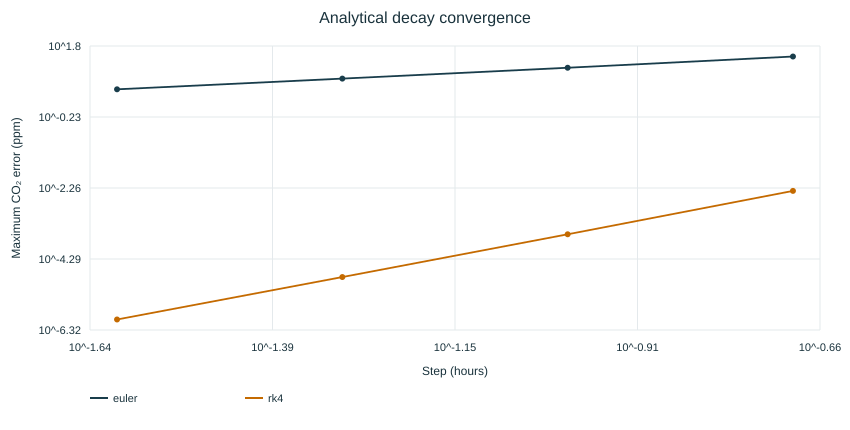

In [3]:
include(joinpath(notebook_root,"verification","benchmarks.jl"))
using .VerificationBenchmarks
decay_room = RoomParameters()
decay_forcing = Forcing(occupants=0, outdoor_temperature_c=25)
decay = solve_ode(constant_rhs(decay_room,decay_forcing,1.0),(1200.0,32.0),(0,2);dt=0.025)
decay_exact = [420+780exp(-t) for t in decay.times]
@assert maximum(abs.(decay.states[1,:]-decay_exact)) < 1e-5
orders = convergence_rows()
for row in orders
    println(row)
end
@assert 0.9 < orders[4].co2_order < 1.2
@assert 3.8 < orders[8].co2_order < 4.3
# Isolate the suite: its own analytical-reference module must not replace
# the notebook's already imported benchmark bindings.
module NotebookVerification
    include(joinpath(Main.notebook_root,"test","runtests.jl"))
end
error_plot = plot(;xscale=:log10,yscale=:log10,xlabel="Step (hours)",ylabel="Maximum CO₂ error (ppm)",title="Analytical decay convergence")
for method in (:euler,:rk4)
    rows = filter(r->r.method==method,orders)
    plot!(error_plot,[r.dt for r in rows],[r.co2_error_ppm for r in rows];marker=:circle,label=string(method))
end
savefig(error_plot,joinpath(notebook_root,"convergence.svg"))
display(error_plot)
println("Analytical comparison, measured error scaling and complete suite passed.")


## 6. Experiments and results

### Fixed strategies

Compare identical inputs and initial conditions. Repeat at half the time step and assert agreement. Peaks are sampled maxima; durations interpolate threshold crossings.


closed (peak_co2_ppm = 5723.827988605869, final_co2_ppm = 5723.827988605869, min_temperature_c = 28.0, peak_temperature_c = 54.72212191065283, final_temperature_c = 54.72212191065283, hours_above_co2 = 1.8393432881616922, hours_below_temperature_band = 0.0, hours_above_temperature_band = 1.9542398165559698, hours_outside_temperature_band = 1.9542398165559698)
partial (peak_co2_ppm = 681.3834622686647, final_co2_ppm = 681.3834622686647, min_temperature_c = 28.0, peak_temperature_c = 31.95796510591492, final_temperature_c = 31.95796510591492, hours_above_co2 = 0.0, hours_below_temperature_band = 0.0, hours_above_temperature_band = 1.9525705591588538, hours_outside_temperature_band = 1.9525705591588538)
full (peak_co2_ppm = 557.1260086624239, final_co2_ppm = 557.1260086624239, min_temperature_c = 28.0, peak_temperature_c = 30.621275749541784, final_temperature_c = 30.621275749541784, hours_above_co2 = 0.0, hours_below_temperature_band = 0.0, hours_above_temperature_band = 1.94702940243894

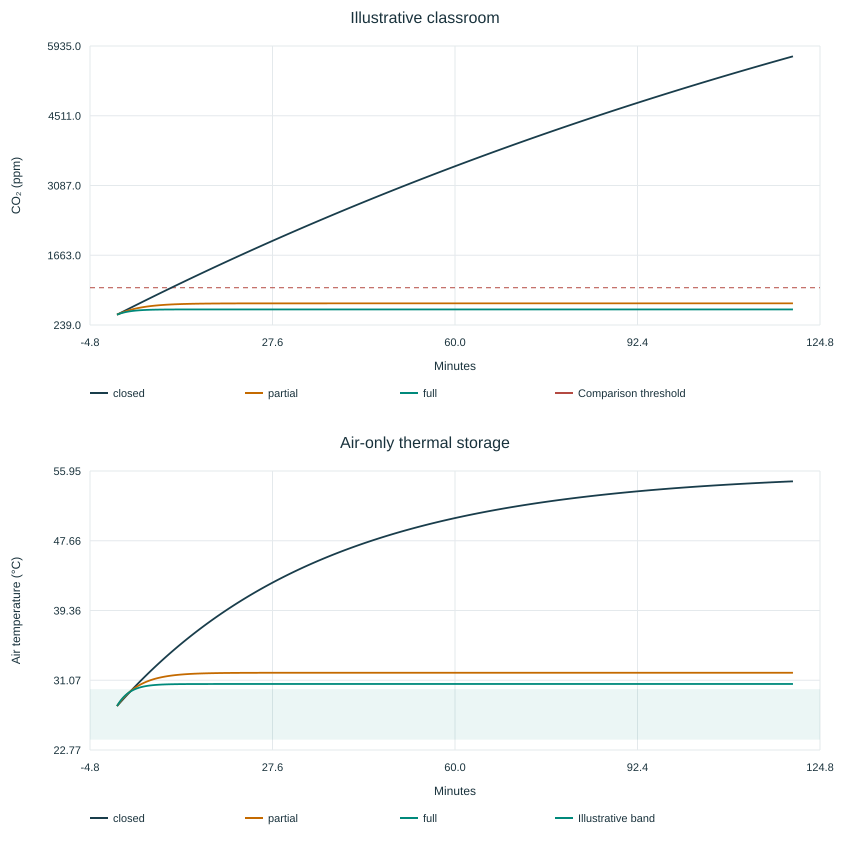

In [4]:
baseline = simulate_fixed_strategies(dt=1/240)
refined = simulate_fixed_strategies(dt=1/480)
for (a,b) in zip(baseline,refined)
    @assert maximum(abs.(a.solution.states[1,:]-b.solution.states[1,1:2:end])) < 0.01
    @assert maximum(abs.(a.solution.states[2,:]-b.solution.states[2,1:2:end])) < 0.001
    println(a.strategy, " ", a.metrics)
end
pc = plot(;xlabel="Minutes",ylabel="CO₂ (ppm)",title="Illustrative classroom")
pt = plot(;xlabel="Minutes",ylabel="Air temperature (°C)",title="Air-only thermal storage")
for r in baseline
    plot!(pc,60 .* r.solution.times,r.solution.states[1,:];label=string(r.strategy))
    plot!(pt,60 .* r.solution.times,r.solution.states[2,:];label=string(r.strategy))
end
hline!(pc,[1000];label="Comparison threshold",linestyle=:dash)
hspan!(pt,[24,30];label="Illustrative band",alpha=.1)
baseline_plot = plot(pc,pt;layout=(2,1),size=(850,850))
savefig(baseline_plot,joinpath(notebook_root,"baseline.svg"))
display(baseline_plot)


### Weather, uncertain inputs and Monte Carlo

The frozen cache is ERA5 reanalysis from Open-Meteo, not classroom measurements. Its original retrieval timestamp is inherited metadata. Whole weekday March 2025 weather blocks at 09:00–11:00 Asia/Colombo preserve paired wind/temperature. Synthetic inputs are exploratory distributions rather than fitted measurements. The code printed above defines every distribution. No weather is silently substituted if checksum validation fails.

Use 500 paired scenarios, seed 4042, RK4 at 7.5 seconds, repeated at 3.75 seconds. Mean intervals quantify Monte Carlo sampling uncertainty conditional on the chosen inputs; outcome percentiles are not mean confidence intervals. Zero observed variance leaves the mean interval unspecified. Event probabilities use Wilson intervals.


Seed=4042; n=500; weather blocks=21
(strategy = :closed, metric = :peak_co2_ppm, n = 500, mean = 5627.544196674575, sd = 1114.2928844570695, mc_standard_error = 49.832692729806524, mean_ci_low = 5529.872118924154, mean_ci_high = 5725.216274424995, p05 = 3927.5131128428807, median = 5532.813149959955, p95 = 7629.433987925318)
(strategy = :closed, metric = :peak_temperature_c, n = 500, mean = 60.15363356288762, sd = 6.934283921123569, mc_standard_error = 0.3101106044583218, mean_ci_low = 59.54581677814931, mean_ci_high = 60.76145034762593, p05 = 50.059901778318086, median = 59.32485072613028, p95 = 71.43348654926986)
(strategy = :closed, metric = :hours_above_co2, n = 500, mean = 1.8329070510836472, sd = 0.03370012918263293, mc_standard_error = 0.0015071155940578332, mean_ci_low = 1.8299531045192938, mean_ci_high = 1.8358609976480005, p05 = 1.7704306944755848, median = 1.8373377437240328, p95 = 1.8785462990334907)
(strategy = :closed, metric = :hours_outside_temperature_band, n = 500, me

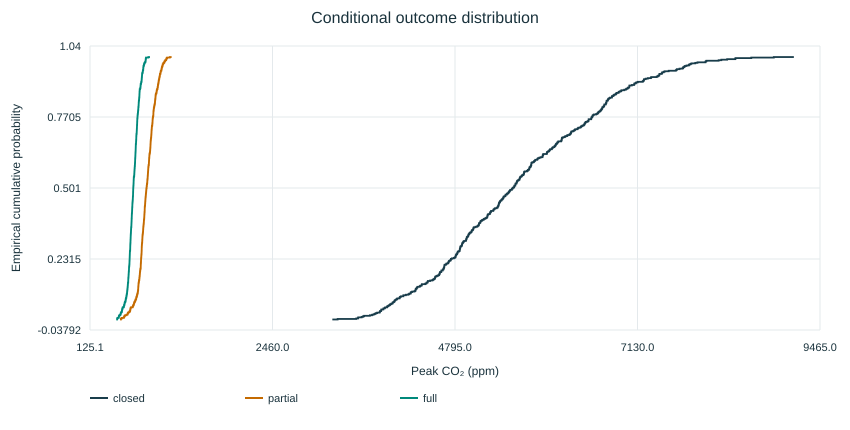

In [5]:
weather_path = joinpath(notebook_root,"data","raw","malabe_era5_2025_03.json")
weather = fetch_weather(weather_path)
profiles = lecture_profiles(weather)
seed, sample_count = 4042, 500
scenarios = sample_scenarios(Xoshiro(seed),profiles,sample_count)
println("Seed=",seed,"; n=",sample_count,"; weather blocks=",length(profiles))
mc = run_monte_carlo(profiles,scenarios;dt=1/480)
@assert length(mc.outcomes)==length(mc.refinements)==3sample_count
summary_rows = NamedTuple[]
for strategy in keys(FIXED_STRATEGIES)
    group = filter(r->r.strategy==strategy,mc.outcomes)
    for metric in (:peak_co2_ppm,:peak_temperature_c,:hours_above_co2,:hours_outside_temperature_band)
        row = merge((;strategy,metric),sample_summary([getproperty(r,metric) for r in group]))
        push!(summary_rows,row)
        println(row)
    end
    println(strategy," CO₂ event probability: ",wilson_interval(count(r->r.hours_above_co2>0,group),sample_count))
end
outcome_plot = plot(;xlabel="Peak CO₂ (ppm)",ylabel="Empirical cumulative probability",title="Conditional outcome distribution")
for strategy in keys(FIXED_STRATEGIES)
    values = sort([r.peak_co2_ppm for r in mc.outcomes if r.strategy==strategy])
    plot!(outcome_plot,values,(1:sample_count)./sample_count;label=string(strategy),seriestype=:steppost)
end
savefig(outcome_plot,joinpath(notebook_root,"mc.svg"))
display(outcome_plot)
write(joinpath(notebook_root,"monte_carlo_summary.json"),JSON.json(summary_rows))
println("Every Monte Carlo outcome passed step refinement.")


### Paired comparisons and sensitivity screening

Negative paired differences mean a reduction relative to the named reference strategy. Spearman correlations describe associations; they are not causal effects or variance shares. Prefix confidence intervals are nested-sample precision checks, not independent replications.


In [6]:
closed = filter(r->r.strategy==:closed,mc.outcomes)
for strategy in (:partial,:full)
    group = filter(r->r.strategy==strategy,mc.outcomes)
    @assert [r.id for r in group]==[r.id for r in closed]
    println(strategy," minus closed peak CO₂: ",sample_summary([a.peak_co2_ppm-b.peak_co2_ppm for (a,b) in zip(group,closed)]))
end
for strategy in keys(FIXED_STRATEGIES)
    group = filter(r->r.strategy==strategy,mc.outcomes)
    y = [r.peak_co2_ppm for r in group]
    for (name,x) in ((:occupants,[s.occupants for s in scenarios]),(:wind_factor,[s.wind_factor for s in scenarios]),(:metabolism,[s.metabolism for s in scenarios]))
        println(strategy," ",name," Spearman rho=",spearman_correlation(x,y))
    end
    for n in filter(n->n<=sample_count,(50,100,250,500))
        println(strategy," prefix ",n,": ",sample_summary(y[1:n]))
    end
end

include(joinpath(notebook_root,"verification","export-results.jl"))

println("TOTAL_NOTEBOOK_SECONDS=", round((time_ns()-notebook_started_ns)/1e9; digits=3))


partial minus closed peak CO₂: (n = 500, mean = -4774.791206321057, sd = 1056.5742706461465, mc_standard_error = 47.25143784884088, mean_ci_low = -4867.404024504785, mean_ci_high = -4682.1783881373285, p05 = -6619.864041167526, median = -4680.479050127425, p95 = -3149.7037265084537)
full minus closed peak CO₂: (n = 500, mean = -4946.187942095041, sd = 1079.2794024730076, mc_standard_error = 48.26684221289999, mean_ci_low = -5040.790952832325, mean_ci_high = -4851.584931357756, p05 = -6857.41342251376, median = -4848.8434202007775, p95 = -3298.5502964545144)
closed occupants Spearman rho=0.8122171068870759
closed wind_factor Spearman rho=0.025110244440977765
closed metabolism Spearman rho=0.4124616178464714
closed prefix 50: (n = 50, mean = 5386.297188139071, sd = 1076.969662078048, mc_standard_error = 152.30651023751446, mean_ci_low = 5087.776428073543, mean_ci_high = 5684.8179482046, p05 = 3936.8165948756778, median = 5194.8900528189715, p95 = 7236.504109826059)
closed prefix 100: (n 

## 7. Discussion and limitations

Interpret the printed results conditionally on the room, weather pool and assumed distributions. Window area, leakage and heat transfer are not measured; only one month and one daily lecture interval are represented. Resampling 21 days does not create new weather information. Air-only heat storage can exaggerate transients. Humidity, mean radiant temperature, wind direction, spatial mixing and full comfort indices are absent. Numerical agreement is not empirical validation. Adaptive control is a future extension.

Public hosting, a fresh free-tier Colab timing test and the owner’s review must be verified separately.


## 8. References

[1] EnergyPlus, Engineering Reference 24.2, Infiltration/Ventilation: https://bigladdersoftware.com/epx/docs/24-2/engineering-reference/infiltration-ventilation.html

[2] A. Persily and L. de Jonge, Carbon Dioxide Generation Rates for Building Occupants, NIST publication record: https://www.nist.gov/publications/carbon-dioxide-generation-rates-building-occupants . Publication record checked; full paper review pending.

[3] Open-Meteo, Historical Weather API: https://open-meteo.com/en/docs/historical-weather-api . Frozen data credit: Open-Meteo.com and Copernicus ERA5, https://doi.org/10.24381/cds.adbb2d47 (inherited identifier).

These references support formulation and input interpretation, not empirical validation. A complete related-work literature review remains separate work.
